# Analyze Extra vs. Intracellular results

Andrew E. Davidson   
aedavids@ucsc.edu  
Date: 2025-10-14.  
Copyright (c) 2020-2027, Regents of the University of California All rights reserved.  
https://polyformproject.org/licenses/noncommercial/1.0.0  

- Figure 5: cfRNA and Intracellular Feature Overlap by Cancer Diagnosis
- Figure 6: Selective cfRNA packaging produces diagnosis-specific transcriptomic differences. 
- Extended Data Figure 6: Differential enrichment of RNA biotypes demonstrates selective cfRNA packaging. 
- Extended Data Figure 7: Selective cfRNA packaging produces diagnosis-specific transcriptomic difference
- Extended Data Figure 8: Selective cfRNA packaging produces diagnosis-specific transcriptomic difference

## 9/21/26 plots volcano plots we want to use in simulation manuscript
These gene loci are expressed in at least 10 % of samples
- title = "extra vs intra TE's. All genes expressed in extra lfc>=2.0 padj<=0.5"
- title = "extra vs intra repeats. All genes expressed in extra lfc>=2.0 padj<=0.5"
- title = "extra vs intra lncRNA. All genes expressed in extra lfc>=2.0 padj<=0.5"

In [1]:
defaultNotebookName="analyzeIntraExtra"

from cliUtilities import configLogging
import logging

# rootLogger = configLogging(logLevel="INFO")
rootLogger = configLogging(logLevel="WARN")
logger = logging.getLogger(__name__)

2026-11-21 16:31:28,943 WARNING cliUtilities.py configLogging() line:61] [BEGIN]
2026-11-21 16:31:28,945 WARNING cliUtilities.py configLogging() line:67] [PYTHONPATH : /private/home/aedavids/graceM/src/python:/private/home/aedavids/graceM/src/jupyterNotebooks]
2026-11-21 16:31:28,946 WARNING cliUtilities.py configLogging() line:68] [FILE: /private/home/aedavids/graceM/src/python/cliUtilities.py]
2026-11-21 16:31:28,947 WARNING cliUtilities.py configLogging() line:69] [PWD: /private/home/aedavids/graceM/src/jupyterNotebooks]


In [2]:
from dataclasses import asdict, dataclass
from IPython.display import display, Image

import matplotlib.pyplot as plt
# set up matplotlib default final artwork complient styles
from plots.plotPanel import natureManuscriptStyle
plt.rcParams.update(natureManuscriptStyle)

from matplotlib.ticker import FuncFormatter, MaxNLocator

from plots.matPlotLibUtilities import MatPlotLibUtilities
from plots.plotUtilities import urlify

# configure for mac
# configure plt to double the resolution of the inline images automatically.
# %config InlineBackend.figure_format = 'retina'
import numpy as np
import os
import pandas as pd
from pathlib import Path

#
# local imports
#
from notebookUtils import appendToPYTHONPATH, getNotebookName
 
ORIG_PYTHONPATH = os.environ['PYTHONPATH']

# extraRNA_PythonPath1 = '/private/home/aedavids/extraCellularRNA' 
extraRNA_PythonPath2 = '/private/home/aedavids/extraCellularRNA/src'

appendToPYTHONPATH([extraRNA_PythonPath2, ]) 

from archive.archiveUtilities import saveFigure
from data.loadCounts import loadDataFrame
from data.dataUtilities import saveList

# from plots.DESeqSelect import stripResultsHeader
from plots.plotPanel import combineFigures, displayPDFInNotebook
from plots.plotPanel import make_panel 
from plots.plotPanel import setFigureFont


from plots.volcanoPlots import createVolcanoData, createVolcanoPanel

from selectFeatures.bestSignatureGeneConfig import BestSignatureGeneConfig

from utilities import runShellCommand, smartDisplay

/private/home/aedavids/miniconda3/envs/graceM/lib/python3.13/site-packages/fitz/__init__.py:17: FutureWarning: The `fitz` API is deprecated and will be removed in future. Use `import pymupdf` instead.
  warnings.warn(
2026-11-21 16:31:31,442 WARNING notebookUtils.py appendToPYTHONPATH() line:40] [Updated PYTHONPATH: /private/home/aedavids/graceM/src/python:/private/home/aedavids/graceM/src/jupyterNotebooks:/private/home/aedavids/extraCellularRNA/src]
/private/home/aedavids/miniconda3/envs/graceM/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
# global, used to filter biotypes to display
MIN_PRECENTAGE_THRESHOLD_G = 1.0

In [4]:
notebookName, notebookDir = getNotebookName(defaultNotebookName)
print(f'notebookName: {notebookName}')
print(f'notebookDir: {notebookDir}')
notebookOutDir = f'{notebookDir}/{notebookName}.out'

imgOutDir = f'{notebookOutDir}/img'
os.makedirs(imgOutDir, exist_ok=True)

imgPanelOutDir = f'{imgOutDir}/panel'
os.makedirs(imgPanelOutDir, exist_ok=True)

dataOutDir = f'/scratch/aedavids/graceM/{notebookName}.out'
os.makedirs(dataOutDir, exist_ok=True)

tmpDir = f'{dataOutDir}/tmp'
os.makedirs(tmpDir, exist_ok=True)

notebookName: analyzeIntraExtra
notebookDir: /private/home/aedavids/graceM/src/jupyterNotebooks


In [5]:
# !ls /private/groups/kimlab/data/elifeGTExTCGA/cromwell.output/*/*
# other files sufixes *.estimatedSizeFactors.csv and  .results.lfcShrink
dataRoot = f'/private/grodowns/kimlab/data/elifeGTExTCGA/cromwell.output/'
allFeatureResultsFiles = !ls /private/groups/kimlab/data/elifeGTExTCGA/cromwell.output/*/*.results
allFeatureResultsFiles

['/private/groups/kimlab/data/elifeGTExTCGA/cromwell.output/Colorectal/intra_vs_all.results',
 '/private/groups/kimlab/data/elifeGTExTCGA/cromwell.output/Esophagus/intra_vs_all.results',
 '/private/groups/kimlab/data/elifeGTExTCGA/cromwell.output/Healthy/intra_vs_all.results',
 '/private/groups/kimlab/data/elifeGTExTCGA/cromwell.output/Liver/intra_vs_all.results',
 '/private/groups/kimlab/data/elifeGTExTCGA/cromwell.output/Lung/intra_vs_all.results',
 '/private/groups/kimlab/data/elifeGTExTCGA/cromwell.output/Stomach/intra_vs_all.results']

In [6]:
repeatInfoFilePath = '/private/groups/kimlab/genomes.annotations/genomes.annotations/gencode.39/named_ucsc.rmsk.insert.info.txt'
print(repeatInfoFilePath)
repeatDF_G = pd.read_csv(repeatInfoFilePath, sep="\t", index_col='insert')
print(f'repeatDF_G.shape : {repeatDF_G.shape}')
repeatDF_G.iloc[0:5, :]

/private/groups/kimlab/genomes.annotations/genomes.annotations/gencode.39/named_ucsc.rmsk.insert.info.txt
repeatDF_G.shape : (15625, 2)


,clade,family
insert,,
(TAACCC)n,Simple_repeat,Simple_repeat
TAR1,Satellite,telo
L1MC5a,LINE,L1
MER5B,DNA,hAT-Charlie
MIR3,SINE,MIR


In [7]:
def createTENames( outDir : str,  repeatDF : pd.DataFrame ) -> str:
    ''' 
    volcanPlots.py uses file I/O save list to file

    
    arguments:
        outDir :
        
        repeatDF :
            example : /private/groups/kimlab/genomes.annotations/genomes.annotations/gencode.39/named_ucsc.rmsk.insert.info.txt
            
                        clade	family
            insert		
            (TAACCC)n	Simple_repeat	Simple_repeat
            TAR1	    Satellite	    telo
            L1MC5a	    LINE	        L1
            MER5B	    DNA	            hAT-Charlie
            MIR3	    SINE	        MIR
        
    return path to a file with list of TE name we want to color in volcano plots
    '''
    # get names of TE's we want to color
    TECladeSet = set( ['SINE', 'LINE', 'LTR'] )
    selectTERows = repeatDF.loc[:, 'clade'].isin( TECladeSet )
    print(f'len(selectTERows) : {len(selectTERows)} sum : {selectTERows.sum()} ')
    TE_DF = repeatDF.loc[selectTERows, :]

    # save namesto temp file
    geneNamesPath = f'{outDir}/createTENames.txt'
    saveList(geneNamesPath, TE_DF.index.values, isSingleItemLine=True )
    logger.warning(f'saved : {saveList}')

    return geneNamesPath

In [8]:
TENamesPath_G = createTENames(tmpDir, repeatDF_G)

2026-11-21 16:31:32,189 WARNING 1927547094.py createTENames() line:31] [saved : <function saveList at 0x7f689cdf2e80>]


len(selectTERows) : 15625 sum : 835 
saved: /scratch/aedavids/graceM/analyzeIntraExtra.out/tmp/createTENames.txt


In [9]:
volcanoTEDataDict = createVolcanoData(
                        allFeatureResultsFiles,
                        geneNamePath=TENamesPath_G
                        )

## <span style="color:red;background-color:yellow;">create panels</span>

2026-11-21 16:31:33,001 WARNING volcanoPlots.py plot() line:355] [AEDWIP TODO move coloring to createVolcanoPlot so we can add a legend in future see createVolcanoPlot()]
2026-11-21 16:31:33,813 WARNING volcanoPlots.py plot() line:355] [AEDWIP TODO move coloring to createVolcanoPlot so we can add a legend in future see createVolcanoPlot()]
2026-11-21 16:31:34,491 WARNING volcanoPlots.py plot() line:355] [AEDWIP TODO move coloring to createVolcanoPlot so we can add a legend in future see createVolcanoPlot()]
2026-11-21 16:31:35,267 WARNING volcanoPlots.py plot() line:355] [AEDWIP TODO move coloring to createVolcanoPlot so we can add a legend in future see createVolcanoPlot()]
2026-11-21 16:31:35,931 WARNING volcanoPlots.py plot() line:355] [AEDWIP TODO move coloring to createVolcanoPlot so we can add a legend in future see createVolcanoPlot()]
2026-11-21 16:31:36,613 WARNING volcanoPlots.py plot() line:355] [AEDWIP TODO move coloring to createVolcanoPlot so we can add a legend in future

'/private/home/aedavids/graceM/src/jupyterNotebooks/analyzeIntraExtra.out/img/panel/_extra-vs-intra-TEs-all-gene-loci.png'

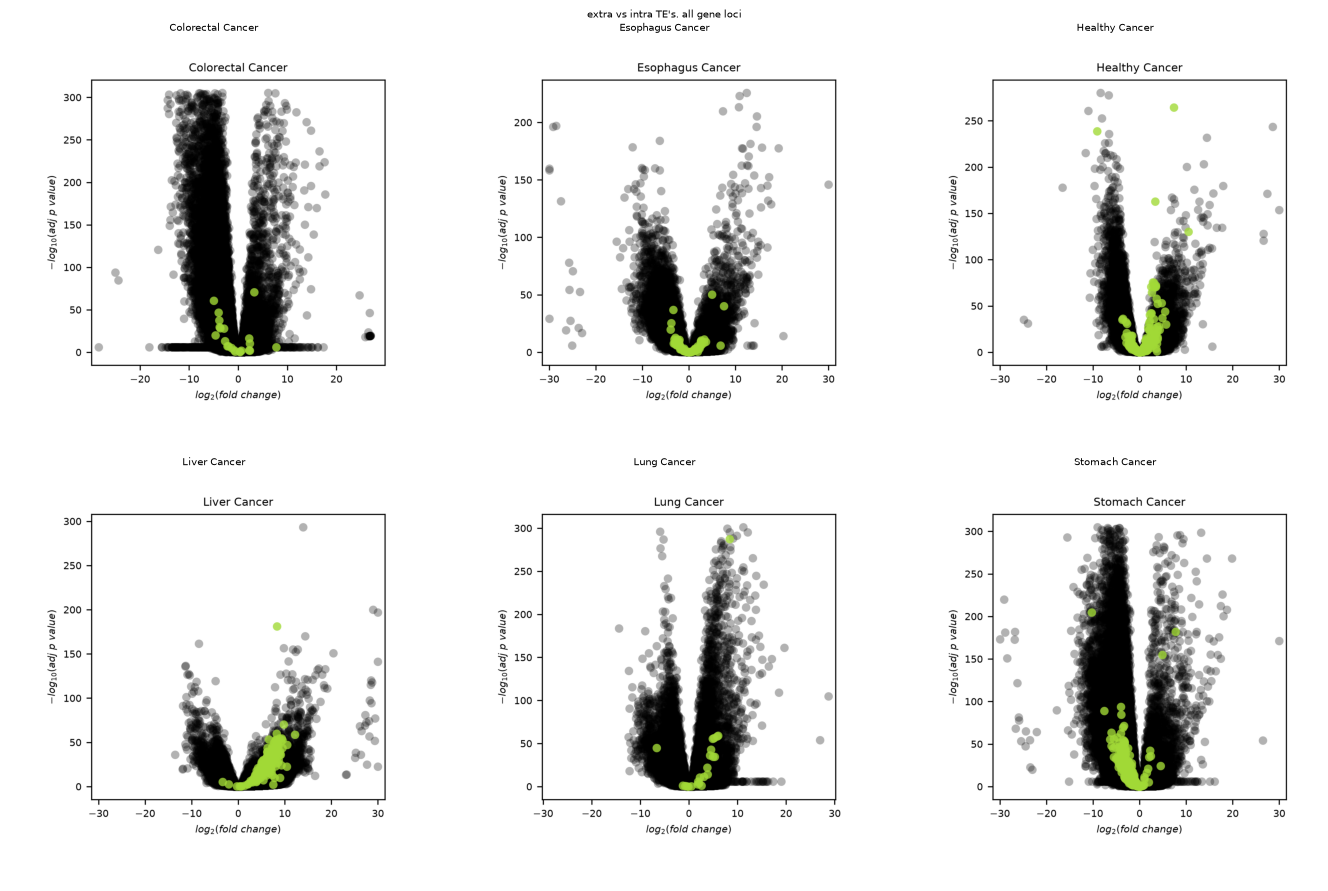

In [10]:
tePanelFig, teFigList = createVolcanoPanel(volcanoTEDataDict, 
                                           label=False, # volcanoTEDataDict contains color info how ever we do not want to display gene id
                                           )
title = "extra vs intra TE's. all gene loci" 
tePanelFig.suptitle( title )
# tight_layout() prevent fig title from overlaying plot
tePanelFig.tight_layout()

saveFigure(tePanelFig, title, imgPanelOutDir)

# <span style="color:red;background-color:yellow;">Selected results features for genes expressed in Elife</span>
we have over 77k features. we expect many feature will only be expressed in tissue. By selecting only
features expressed in extracellular we should get more meaningful volcano plots

In [11]:
def filterGenesByDetectionRate(
        countDF : pd.DataFrame,
        expressionRate : float,
    ) -> pd.DataFrame:
    ''' 
    
    arguments :
        countDF
            index = id
                the index does not mater. 
                example of ids : 
                    assigned by pd.read_csv(), transcript_id, gene name, ...
            columns 
                are typically sample is.
                the column names do not mater
                
        
        expressionRate
            example 0.20
            
    raise TypeError is any of the columns are not numeric dtypes
    '''
    # list comprehension formated across 3 lines
    nonNumericCols: list[str] = [col 
                                    for col in countDF.columns 
                                    if not pd.api.types.is_numeric_dtype(countDF[col])
                                ]

    if nonNumericCols:
        raise TypeError(f"Non-numeric columns: {nonNumericCols}")

    
    
    # create a logical dataframe True if value > 0
    greaterThanDF = countDF > expressionRate
    
    nCols = countDF.shape[1]
    nSamples = nCols
    
    # for each gene find the number of sample for which it is express
    byRow = 1
    sampleWithExpresionSeries = greaterThanDF.sum(axis=byRow)
    
    # select genes that are expressed in at least 70% of the samples
    featuresWeWantSeries = sampleWithExpresionSeries > nSamples * 0.7

    return countDF.loc[featuresWeWantSeries, :]
    
####### test
def testFilterGenesByDetectionRate() :
    
    #         s1	s2	s3	s4	s5
    # g1	7	5	1	10	10
    # g2	1	0	0	3	3
    # g3	2	7	2	0	5
    ffDF = filterGenesByDetectionRate(countDF = pd.DataFrame(
                                                    {
                                                        "s1" : [7, 1, 2],
                                                        "s2" : [5, 0, 7],
                                                        "s3" : [1, 0, 2],
                                                        "s4" : [10, 3, 0],            
                                                        "s5" : [10, 3, 5],            
                                                    },
                                                    index = ['g1', 'g2', 'g3']
                                                ),
                                expressionRate=0.7)
    
    #      s1	s2	s3	s4	s5
    # g1	7	5	1	10	10
    # g3	2	7	2	0	5
    expectedDF = pd.DataFrame(
                                {
                                    "s1" : [7, 2],
                                    "s2" : [5, 7],
                                    "s3" : [1, 2],
                                    "s4" : [10, 0],            
                                    "s5" : [10, 5],            
                                },
                                index = ['g1',  'g3']
                            )
    
    pd.testing.assert_frame_equal(ffDF, expectedDF)

testFilterGenesByDetectionRate()

In [12]:
def loadElifeGTExTCGADataSet() -> tuple[pd.DataFrame, pd.DataFrame, pd.DataFrame]:
    ''' 
    TODO
    '''
    countDataDir = f'/private/groups/kimlab/data/elifeGTExTCGA/selectIntracellularSamples.out'
    
    elifeGTExTCGACountFile = f'{countDataDir}/elifeGTExTCGA_count.csv'
    elifeGTExTCGACountDF= loadDataFrame(elifeGTExTCGACountFile)
    elifeGTExTCGACountDF.set_index("geneId", inplace=True)
    print(f'countDataDir.shape : {elifeGTExTCGACountDF.shape}')
    display(elifeGTExTCGACountDF.iloc[0:5, 0:4])
    
    elifeGTExTCGAMetaFile = f'{countDataDir}/elifeGTExTCGA_metaData.csv'
    elifeGTExTCGAMetaDF= loadDataFrame(elifeGTExTCGAMetaFile)
    elifeGTExTCGAMetaDF.set_index('sample_id', inplace=True)
    print(f'elifeGTExTCGAMetaDF.shape : {elifeGTExTCGAMetaDF.shape}')
    display(elifeGTExTCGAMetaDF.head())
    
    elifeGTExTCGABiotypeFile = f'{countDataDir}/elifeGTExTCGA_bioTypes.csv'
    elifeGTExTCGABiotypeDF= loadDataFrame(elifeGTExTCGABiotypeFile)
    elifeGTExTCGABiotypeDF.set_index('geneId', inplace=True)
    print(f'elifeGTExTCGABiotypeDF.shape : {elifeGTExTCGABiotypeDF.shape}')
    display(elifeGTExTCGABiotypeDF.head())
    
    return (elifeGTExTCGACountDF, elifeGTExTCGAMetaDF, elifeGTExTCGABiotypeDF)
    
    
elifeGTExTCGACountDF, elifeGTExTCGAMetaDF, elifeGTExTCGABiotypeDF = loadElifeGTExTCGADataSet()

2026-11-21 16:32:08,478 WARNING loadCounts.py loadDataFrame() line:164] [loading : /private/groups/kimlab/data/elifeGTExTCGA/selectIntracellularSamples.out/elifeGTExTCGA_count.pandas.h5]


countDataDir.shape : (74352, 452)


/data/tmp/ipykernel_2244587/2839342645.py:9: Pandas4Warning: The inplace keyword in DataFrame.set_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  elifeGTExTCGACountDF.set_index("geneId", inplace=True)


,COAD-3L-AA1B-TP,COAD-4T-AA8H-TP,COAD-5M-AAT6-TP,COAD-A6-5665-TP
geneId,,,,
(A)n,9,5,25,88
(AAA)n,0,0,0,0
(AAAAAAC)n,0,0,0,0
(AAAAAAG)n,0,0,0,0
(AAAAAAT)n,0,0,0,0


2026-11-21 16:32:09,158 WARNING loadCounts.py loadDataFrame() line:181] [loading : /private/groups/kimlab/data/elifeGTExTCGA/selectIntracellularSamples.out/elifeGTExTCGA_metaData.csv]


elifeGTExTCGAMetaDF.shape : (446, 6)


... (2 outputs left out)

2026-11-21 16:32:09,171 WARNING loadCounts.py loadDataFrame() line:181] [loading : /private/groups/kimlab/data/elifeGTExTCGA/selectIntracellularSamples.out/elifeGTExTCGA_bioTypes.csv]


elifeGTExTCGABiotypeDF.shape : (74352, 1)


/data/tmp/ipykernel_2244587/2839342645.py:21: Pandas4Warning: The inplace keyword in DataFrame.set_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  elifeGTExTCGABiotypeDF.set_index('geneId', inplace=True)


,bioType
geneId,
(A)n,repeatMask
(AAA)n,repeatMask
(AAAAAAC)n,repeatMask
(AAAAAAG)n,repeatMask
(AAAAAAT)n,repeatMask


In [13]:
def createRepeatMaskBiomakerNames( outDir : str,  
                                  bioTypesDF : pd.DataFrame,
                                  bioTypes : list[str]
                                  ) -> str:
    ''' 
    volcanPlots.py uses file I/O save list to file
    
    arguments:
        outDir :
        
        bioTypeDF example

                    bioType
        geneId	
        (A)n	    repeatMask
        (AAA)n	    repeatMask
        (AAAAAAC)n	repeatMask
        (AAAAAAG)n	repeatMask
        (AAAAAAT)n	repeatMask
        
        geneIds :
            list of bioTypes to color
        
        
    return path to a file with list of geneIds we want to color in volcano plots
    '''
    # get names of TE's we want to color
    TECladeSet = set( ['SINE', 'LINE', 'LTR'] )
    selectTERows = bioTypesDF.loc[:, 'bioType'].isin( bioTypes )
    print(f'len(selectTERows) : {len(selectTERows)} sum : {selectTERows.sum()} ')
    retDF = bioTypesDF.loc[selectTERows, :]

    # save names to temp file
    
    tmp = " ".join(bioTypes)
    bioTypesStr = "_".join(tmp.split())
    geneNamesPath = f'{outDir}/{bioTypesStr}BioTypeNames.txt'
    saveList(geneNamesPath, retDF.index.values, isSingleItemLine=True )
    logger.warning(f'saved : {saveList}')

    return geneNamesPath

In [14]:
# create file with a list of repeatMask biomaker genes we want 
# to color in the volcano plot
repeatBiomarkerNamesPath_G = createRepeatMaskBiomakerNames( tmpDir, elifeGTExTCGABiotypeDF, ['repeatMask'])

2026-11-21 16:32:09,282 WARNING 1333953956.py createRepeatMaskBiomakerNames() line:39] [saved : <function saveList at 0x7f689cdf2e80>]


len(selectTERows) : 74352 sum : 15297 
saved: /scratch/aedavids/graceM/analyzeIntraExtra.out/tmp/repeatMaskBioTypeNames.txt


In [15]:
# create file with a list of lncRNA biomaker genes we want 
# to color in the volcano plot
lncRNABiomarkerNamesPath_G = createRepeatMaskBiomakerNames( tmpDir, elifeGTExTCGABiotypeDF, ['lncRNA'])

2026-11-21 16:32:09,303 WARNING 1333953956.py createRepeatMaskBiomakerNames() line:39] [saved : <function saveList at 0x7f689cdf2e80>]


len(selectTERows) : 74352 sum : 16388 
saved: /scratch/aedavids/graceM/analyzeIntraExtra.out/tmp/lncRNABioTypeNames.txt


In [16]:
def filterDESeqResultsByExpressionRate(
        metaDF : pd.DataFrame,
        countDF : pd.DataFrame,
        dataSet : str,
        fileName : str,
        expressionRate : float=0.1, # gets rid of noise
    ) -> list[str]:
    ''' 
    TODO
    
    Returns a list of DESeq result files, one for each diagnosis, 
    containing only genes expressed in the eLife dataset.
    
    arguments:
        expressionRate
            example : 0.1
            
            selectes features that are expressed in >= 10% of sample
            
        dataSet :
            either 'elife', 'GTEx', or'TCGA'
            
        fileName :
            example 'expressedInElife.results'
    '''
    
    validDataSets = ['elife', 'GTEx', 'TCGA']
    if not dataSet in validDataSets :
        emsg = f'dataSet {dataSet} not in {validDataSets}'
        raise ValueError(emsg)
        
    resultsPathList = list()
    diagnosisSeries = metaDF.loc[:, "elifeDiagnosis"].unique()
    logger.warning(f"AEDWIP TODO make generic pass dataSet, save file name ex expressedInElife.results" )
    
    for diagnosis in diagnosisSeries:
        # select the sample ids from the meta data for the elife diagnosis
        print(f'\ndiagnosis : {diagnosis}')
        # selectRows=  (metaDF['elifeDiagnosis'] == diagnosis) & (metaDF['dataSet'] == 'elife')
        selectRows=  (metaDF['elifeDiagnosis'] == diagnosis) & (metaDF['dataSet'] == dataSet)
        diagnosticSamplesMetaDF = metaDF.loc[selectRows, :]
        print(f'diagnosticSamplesMetaDF.shape : {diagnosticSamplesMetaDF.shape}')        
                        
        # select the elife counts for samples
        diagnosticSamplesCountDF = countDF.loc[:, diagnosticSamplesMetaDF.index]
        print(f'diagnosticSamplesCountDF.shape : {diagnosticSamplesCountDF.shape}')
        
        # select the features that are expressed 
        expressedCountsDF = filterGenesByDetectionRate(diagnosticSamplesCountDF, expressionRate)
        print(f'expressedCountsDF.shape : {expressedCountsDF.shape}')
        
        expressedGenesSeries = expressedCountsDF.index
        print(f'expressedGenesSeries.shape : {expressedGenesSeries.shape}')
        # print(f'{expressedGenesSeries[0:5]}')
        # print(f'{expressedGenesSeries[-5:]}')
        
        # load the deseq results file for the diagnosis
        resultsRootDir = "/private/groups/kimlab/data/elifeGTExTCGA/cromwell.output"
        dianosisDirName = diagnosis.split(" ")[0]
        resultsPath = f'{resultsRootDir}/{dianosisDirName}/intra_vs_all.results'
        resultsDF = pd.read_csv(resultsPath, skiprows=7, index_col='name')
        print(f'resultsDF.shape : {resultsDF.shape}')
        # display(resultsDF.head())
        
        # select the feature that where expressed in elife for the diagnosis
        resultsExpressedInElifeDF = resultsDF.loc[expressedGenesSeries , :]
        print(f'resultsExpressedInElifeDF.shape : {resultsExpressedInElifeDF.shape}')
        
        # save the, include the index
        expressedInElifeResultsPathDir = f'{dataOutDir}/{dianosisDirName}'
        os.makedirs(expressedInElifeResultsPathDir, exist_ok=True)
        expressedInElifeResultsPath = f'{expressedInElifeResultsPathDir}/{fileName}'
        resultsExpressedInElifeDF.to_csv(expressedInElifeResultsPath)
        print(f'saved: {expressedInElifeResultsPath}')
        
        resultsPathList.append(expressedInElifeResultsPath)

    return sorted( resultsPathList )
    
######################################################################
elifeResultsPathList = filterDESeqResultsByExpressionRate(
                            expressionRate=0.1,
                            metaDF = elifeGTExTCGAMetaDF,
                            countDF = elifeGTExTCGACountDF,
                            dataSet='elife',
                            fileName='expressedInElife.results'
                        )

print(f'\nelifeResultsPathList:')
elifeResultsPathList

2026-11-21 16:32:09,320 WARNING 2217676454.py filterDESeqResultsByExpressionRate() line:34] [AEDWIP TODO make generic pass dataSet, save file name ex expressedInElife.results]



diagnosis : Esophagus Cancer
diagnosticSamplesMetaDF.shape : (31, 6)
diagnosticSamplesCountDF.shape : (74352, 31)
expressedCountsDF.shape : (12084, 31)
expressedGenesSeries.shape : (12084,)
resultsDF.shape : (74352, 6)
resultsExpressedInElifeDF.shape : (12084, 6)
saved: /scratch/aedavids/graceM/analyzeIntraExtra.out/Esophagus/expressedInElife.results

diagnosis : Lung Cancer
diagnosticSamplesMetaDF.shape : (35, 6)
diagnosticSamplesCountDF.shape : (74352, 35)
expressedCountsDF.shape : (14256, 35)
expressedGenesSeries.shape : (14256,)
resultsDF.shape : (74352, 6)
resultsExpressedInElifeDF.shape : (14256, 6)
saved: /scratch/aedavids/graceM/analyzeIntraExtra.out/Lung/expressedInElife.results

diagnosis : Liver Cancer
diagnosticSamplesMetaDF.shape : (26, 6)
diagnosticSamplesCountDF.shape : (74352, 26)
expressedCountsDF.shape : (14605, 26)
expressedGenesSeries.shape : (14605,)
resultsDF.shape : (74352, 6)
resultsExpressedInElifeDF.shape : (14605, 6)
saved: /scratch/aedavids/graceM/analyzeIn

['/scratch/aedavids/graceM/analyzeIntraExtra.out/Colorectal/expressedInElife.results',
 '/scratch/aedavids/graceM/analyzeIntraExtra.out/Esophagus/expressedInElife.results',
 '/scratch/aedavids/graceM/analyzeIntraExtra.out/Healthy/expressedInElife.results',
 '/scratch/aedavids/graceM/analyzeIntraExtra.out/Liver/expressedInElife.results',
 '/scratch/aedavids/graceM/analyzeIntraExtra.out/Lung/expressedInElife.results',
 '/scratch/aedavids/graceM/analyzeIntraExtra.out/Stomach/expressedInElife.results']

In [17]:
# black
volcanoElifeDataDict = createVolcanoData(
                        elifeResultsPathList,
                        geneNamePath=None # do not color volcano plot
                        )

# debugVolcanoDataDict( volcanoElifeDataDict )

2026-11-21 16:32:11,751 WARNING volcanoPlots.py plot() line:355] [AEDWIP TODO move coloring to createVolcanoPlot so we can add a legend in future see createVolcanoPlot()]
2026-11-21 16:32:11,905 WARNING volcanoPlots.py plot() line:355] [AEDWIP TODO move coloring to createVolcanoPlot so we can add a legend in future see createVolcanoPlot()]
2026-11-21 16:32:12,072 WARNING volcanoPlots.py plot() line:355] [AEDWIP TODO move coloring to createVolcanoPlot so we can add a legend in future see createVolcanoPlot()]
2026-11-21 16:32:12,263 WARNING volcanoPlots.py plot() line:355] [AEDWIP TODO move coloring to createVolcanoPlot so we can add a legend in future see createVolcanoPlot()]
2026-11-21 16:32:12,449 WARNING volcanoPlots.py plot() line:355] [AEDWIP TODO move coloring to createVolcanoPlot so we can add a legend in future see createVolcanoPlot()]
2026-11-21 16:32:12,651 WARNING volcanoPlots.py plot() line:355] [AEDWIP TODO move coloring to createVolcanoPlot so we can add a legend in future

'/private/home/aedavids/graceM/src/jupyterNotebooks/analyzeIntraExtra.out/img/panel/_extra-vs-intra-All-genes-expressed-in-extra.png'

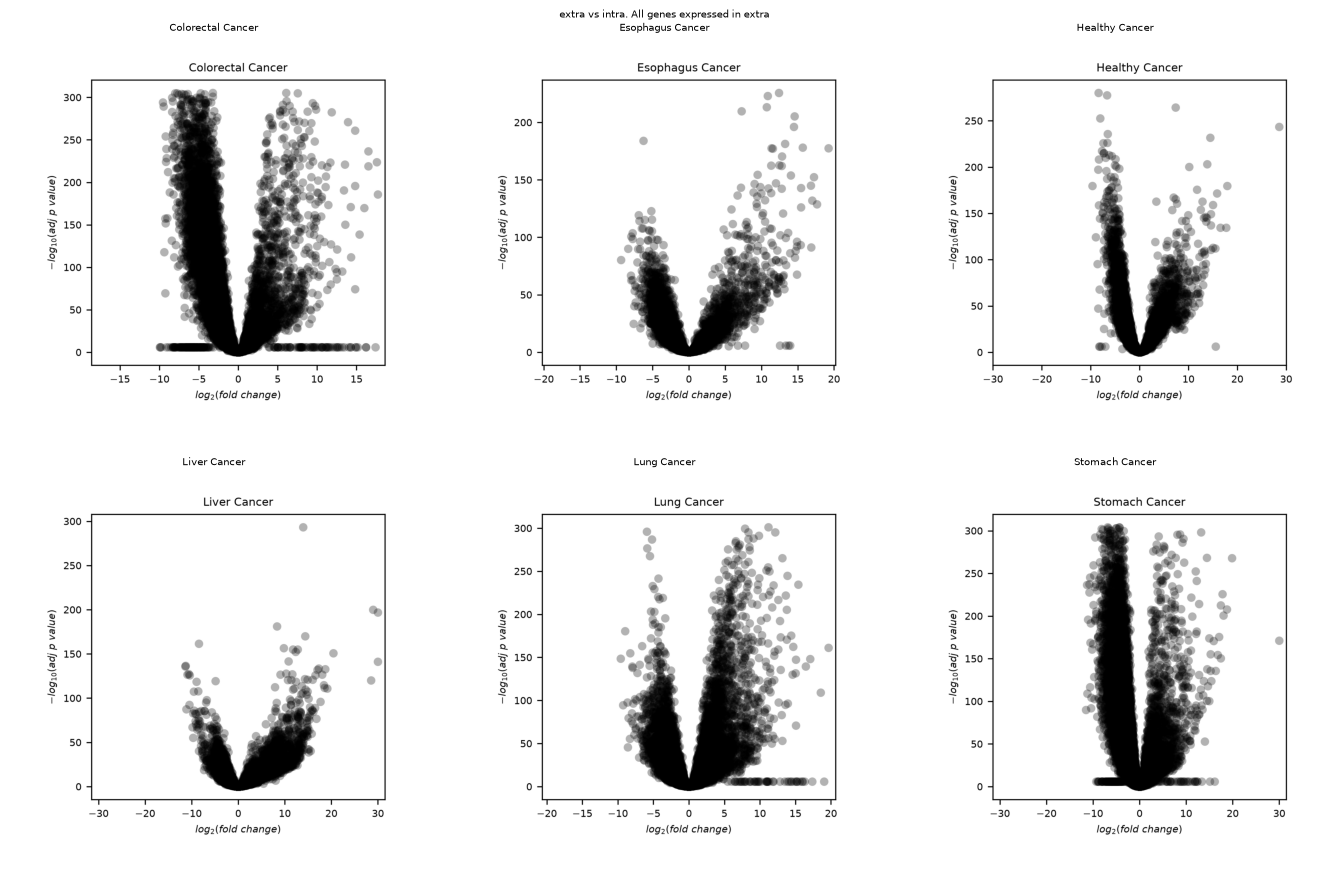

In [18]:
# 9/21/26 do not use in manuscript
elifePanelFig, elifeFigList = createVolcanoPanel(volcanoElifeDataDict,
                                    numHeaderLines=1,
                                   )
title = "extra vs intra. All genes expressed in extra"
elifePanelFig.suptitle( title )
# tight_layout() prevent fig title from overlaying plot
elifePanelFig.tight_layout()
saveFigure(elifePanelFig, title, imgPanelOutDir)

2026-11-21 16:32:40,393 WARNING volcanoPlots.py plot() line:355] [AEDWIP TODO move coloring to createVolcanoPlot so we can add a legend in future see createVolcanoPlot()]
2026-11-21 16:32:40,549 WARNING volcanoPlots.py plot() line:355] [AEDWIP TODO move coloring to createVolcanoPlot so we can add a legend in future see createVolcanoPlot()]
2026-11-21 16:32:40,718 WARNING volcanoPlots.py plot() line:355] [AEDWIP TODO move coloring to createVolcanoPlot so we can add a legend in future see createVolcanoPlot()]
2026-11-21 16:32:40,912 WARNING volcanoPlots.py plot() line:355] [AEDWIP TODO move coloring to createVolcanoPlot so we can add a legend in future see createVolcanoPlot()]
2026-11-21 16:32:41,097 WARNING volcanoPlots.py plot() line:355] [AEDWIP TODO move coloring to createVolcanoPlot so we can add a legend in future see createVolcanoPlot()]
2026-11-21 16:32:41,303 WARNING volcanoPlots.py plot() line:355] [AEDWIP TODO move coloring to createVolcanoPlot so we can add a legend in future

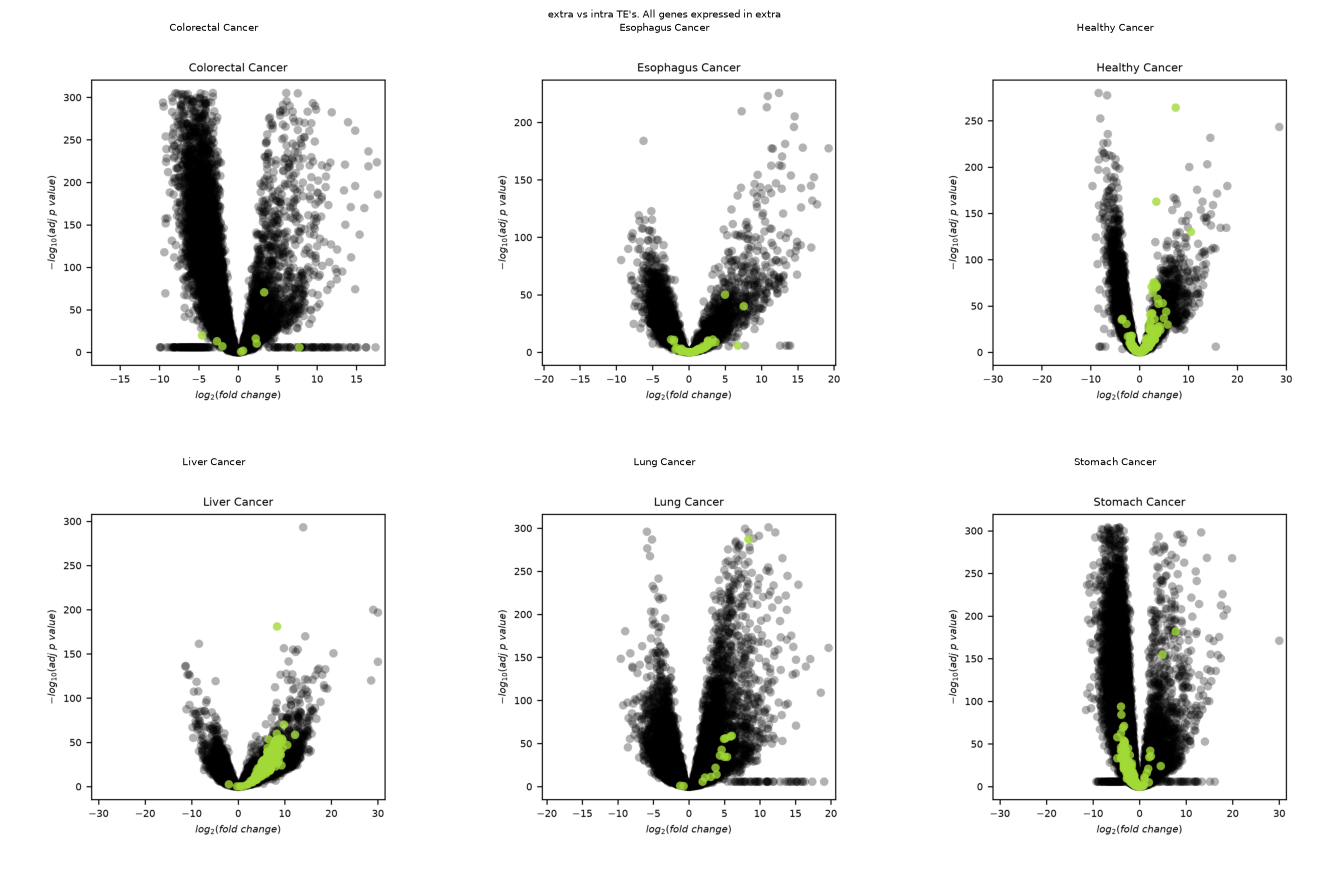

In [19]:
def createVolcanoPlotTE_expressedInExtra():
    ''' 
    9/21/26 do not use in manuscript. Use lfc,padj expressed in extra volcano plot
    '''
    # black and green default color
    volcanoElifeTEDataDict = createVolcanoData(
                            elifeResultsPathList,
                            geneNamePath=TENamesPath_G # color these points in volcano plot
                            )

    elifeTEPanelFig, elifeTEFigList = createVolcanoPanel(volcanoElifeTEDataDict,
                                        numHeaderLines=1,
                                        label=False # volcanoElifeTEDataDict has color info, do not dislay gene loci
                                    )

    for fig in elifeTEFigList:
        fig.tight_layout()
        teOutDir = f'{imgPanelOutDir}/signifigantTE_ExpressedIn0.1'
        
        ax = fig.get_axes()[0]
        title = ax.get_title()
        # tight_layout() prevent fig title from overlaying plot
        fig.tight_layout()
        saveFigure(fig, title, teOutDir)

    title = "extra vs intra TE's. All genes expressed in extra"
    elifeTEPanelFig.suptitle( title )
    # tight_layout() prevent fig title from overlaying plot
    elifeTEPanelFig.tight_layout()
    saveFigure(elifeTEPanelFig, title, imgPanelOutDir)
    
createVolcanoPlotTE_expressedInExtra()

# <span style="color:red;background-color:yellow;">Are transcripts selectively packaged?</span>
Are there  features that are expressed in intra but not extra?

In [20]:
gtexResultsPathList = filterDESeqResultsByExpressionRate(
                            expressionRate=0.1,
                            metaDF = elifeGTExTCGAMetaDF,
                            countDF = elifeGTExTCGACountDF,
                            dataSet='GTEx',
                            fileName='expressedInGTEx.results'
                        )

tcgaResultsPathList = filterDESeqResultsByExpressionRate(
                            expressionRate=0.1,
                            metaDF = elifeGTExTCGAMetaDF,
                            countDF = elifeGTExTCGACountDF,
                            dataSet='TCGA',
                            fileName='expressedInTCGA.results'
                        )

print(f'\n****** gtexResultsPathList ')
for f in gtexResultsPathList :
    print(f)

print(f'\n****** tcgaResultsPathList')
for f in tcgaResultsPathList :
    print(f)

2026-11-21 16:33:16,660 WARNING 2217676454.py filterDESeqResultsByExpressionRate() line:34] [AEDWIP TODO make generic pass dataSet, save file name ex expressedInElife.results]



diagnosis : Esophagus Cancer
diagnosticSamplesMetaDF.shape : (0, 6)
diagnosticSamplesCountDF.shape : (74352, 0)
expressedCountsDF.shape : (0, 0)
expressedGenesSeries.shape : (0,)
resultsDF.shape : (74352, 6)
resultsExpressedInElifeDF.shape : (0, 6)
saved: /scratch/aedavids/graceM/analyzeIntraExtra.out/Esophagus/expressedInGTEx.results

diagnosis : Lung Cancer
diagnosticSamplesMetaDF.shape : (0, 6)
diagnosticSamplesCountDF.shape : (74352, 0)
expressedCountsDF.shape : (0, 0)
expressedGenesSeries.shape : (0,)
resultsDF.shape : (74352, 6)
resultsExpressedInElifeDF.shape : (0, 6)
saved: /scratch/aedavids/graceM/analyzeIntraExtra.out/Lung/expressedInGTEx.results

diagnosis : Liver Cancer
diagnosticSamplesMetaDF.shape : (0, 6)
diagnosticSamplesCountDF.shape : (74352, 0)
expressedCountsDF.shape : (0, 0)
expressedGenesSeries.shape : (0,)
resultsDF.shape : (74352, 6)
resultsExpressedInElifeDF.shape : (0, 6)
saved: /scratch/aedavids/graceM/analyzeIntraExtra.out/Liver/expressedInGTEx.results

dia

2026-11-21 16:33:17,594 WARNING 2217676454.py filterDESeqResultsByExpressionRate() line:34] [AEDWIP TODO make generic pass dataSet, save file name ex expressedInElife.results]


saved: /scratch/aedavids/graceM/analyzeIntraExtra.out/Healthy/expressedInGTEx.results

diagnosis : Esophagus Cancer
diagnosticSamplesMetaDF.shape : (31, 6)
diagnosticSamplesCountDF.shape : (74352, 31)
expressedCountsDF.shape : (30247, 31)
expressedGenesSeries.shape : (30247,)
resultsDF.shape : (74352, 6)
resultsExpressedInElifeDF.shape : (30247, 6)
saved: /scratch/aedavids/graceM/analyzeIntraExtra.out/Esophagus/expressedInTCGA.results

diagnosis : Lung Cancer
diagnosticSamplesMetaDF.shape : (35, 6)
diagnosticSamplesCountDF.shape : (74352, 35)
expressedCountsDF.shape : (26546, 35)
expressedGenesSeries.shape : (26546,)
resultsDF.shape : (74352, 6)
resultsExpressedInElifeDF.shape : (26546, 6)
saved: /scratch/aedavids/graceM/analyzeIntraExtra.out/Lung/expressedInTCGA.results

diagnosis : Liver Cancer
diagnosticSamplesMetaDF.shape : (26, 6)
diagnosticSamplesCountDF.shape : (74352, 26)
expressedCountsDF.shape : (23435, 26)
expressedGenesSeries.shape : (23435,)
resultsDF.shape : (74352, 6)
re

In [21]:
def selectFeatures(resultsPathList : list[str]) -> dict[str, list[str]] :
    ''' 
    TODO
    given a list of file paths to DESEq results file
    returns a dictionary with key = diagnosis and values = list of feature name
    
    assumes file names end with diagnosis/file name
        example 
            /scratch/aedavids/fagazi/analyzeIntraExtra.out/Colorectal/expressedInTCGA.results
            ends with Colorectal/expressedInTCGA.results
    '''
    retDict = dict()
    for rPath in resultsPathList :
        tokens = rPath.split('/')
        diagnosis = tokens[-2]
        resultsDF = loadDataFrame(rPath)
        # print(resultsDF.head())
        
        geneList = resultsDF['geneId'].to_list()
        print(f'{diagnosis} len(geneList) : {len(geneList)}')

        retDict[diagnosis] = geneList
        
    return retDict

In [22]:
genesExpressedInElifeDict = selectFeatures(elifeResultsPathList)   

2026-11-21 16:33:20,677 WARNING loadCounts.py loadDataFrame() line:181] [loading : /scratch/aedavids/graceM/analyzeIntraExtra.out/Colorectal/expressedInElife.results]


KeyError: 'geneId'

In [ ]:
# TCGA only include cancer type, we get Healthy from GTEx
genesExpressedInTCGADict = selectFeatures(tcgaResultsPathList) 

In [ ]:
# we only include Whole_Blood from GTEx
genesExpressedInGTExDict = selectFeatures(gtexResultsPathList)     

In [ ]:
@dataclass
class SetComparison:
    intersection: set[str]
    interSectionCardinality : int
    
    leftOnly: set[str]
    leftOnlyCardinality : int
    leftCardinality : float

    rightCardinality : float
    rightOnly: set[str]
    rightOnlyCardinality : int
    
    
def compareFeatures(expressDict1 : dict[str, list[str]], 
        expressDict2 : dict[str, list[str]],
    ) -> dict[str, SetComparison]:
    ''' 
    returns a dictionary with key = diagnosis and an item of type SetComparison
    '''
    retDict = dict()
    for diagnosis, featureListLeft in expressDict1.items():
        set1 = set(featureListLeft)
        
        isSet1Empty = False
        if len(featureListLeft) <= 0 :
            isSet1Empty = True
            logger.warning(f'expressDict1 {diagnosis} does not have any features' )  
                 
        featureListRight = expressDict2[diagnosis]
        set2 = set(featureListRight)
        isSet2Empty = False
        if len(featureListRight) <= 0 :
            isSet2Empty = True
            logger.warning(f'expressDict2 {diagnosis} does not have any features' )
            
        if not isSet1Empty and not isSet2Empty :
            set1Only = set1 - set2
            set2Only= set2 - set1
            intersection = set1.intersection( set2 )
            sc = SetComparison( 
                               intersection=intersection, 
                               interSectionCardinality=len(intersection),
                               
                               leftOnly=set1Only, 
                               leftOnlyCardinality=len(set1Only),
                               leftCardinality = len(set1),
                               
                               rightCardinality = len(set2),
                               rightOnly=set2Only,
                               rightOnlyCardinality=len(set2Only)
                               )
            retDict[diagnosis] = sc
            
    return retDict 


In [ ]:
def createComparisionCountDF(comparisonDict :dict[str, SetComparison] ) -> pd.DataFrame:
    ''' 
    returns a data frame with the counts. 
    makes it easy to display 
    '''
    rows: list[dict[str, int | str]] = []

    for key, item in comparisonDict.items():
        rows.append(
            {
                "key": key,
                "nLeft" : item.leftCardinality,
                "nRight" : item.rightCardinality,
                "nLeftOnly": item.leftOnlyCardinality,
                "nIntersection": item.interSectionCardinality,                
                "nRightOnly": item.rightOnlyCardinality,
            }
        )

    retDF = pd.DataFrame(rows)
    retDF.rename(columns={'key':'diagnosis',}, inplace=True)
    retDF.set_index('diagnosis', inplace=True)
    
    return retDF

In [ ]:
elifeVsTCGADict = compareFeatures(genesExpressedInElifeDict, genesExpressedInTCGADict)
print("\n********** elife vs TCGA feature comparison")
print("elife feature sets only includes genes that are expressed in at least 10% of the sample for each diagnosis")
print("TCGA feature sets only includes genes that are expressed in at least 10% of the sample for each diagnosis")
print(f'intra only is evidence for selective packaging')
print(f'extra Only: could be evidence of signal from other cell, tissue, and organ types')
elifeTCGAComparisionDF = createComparisionCountDF( elifeVsTCGADict)

# 10/14/26
# Daniel suggested using different names
# elifeTCGAComparisionDF.rename(columns={'key'        :'diagnosis', 
#                                 'nLeft'      : 'nExtra',
#                                 'nRight'     : 'nIntra',
#                                 'nLeftOnly'  : 'nExtraOnly',
#                                 'nRightOnly' : 'nIntraOnly',
#                                 }, inplace=True)

elifeTCGAComparisionDF.rename(columns={
                                    'key'           :'diagnosis', 
                                    'nLeft'         : "Extracellular\ntotal",
                                    'nRight'        : "Intracellular\ntotal",
                                    'nLeftOnly'     : "Extracellular\nonly",
                                    'nRightOnly'    : "Intracellular\nonly",
                                    'nIntersection' : "Intersection",
                                }, inplace=True)
elifeTCGAComparisionDF

In [ ]:
def plotCountBarchart(
    counts: pd.Series,
    title: str | None = None,
    #figsize: tuple[float, float] = (4, 3.5),
    labelRotation: float = 45,
    #ax=None,
    panelWidthInMM : int = 180,
    panelHeightInMM : int = 185,
    nPanelColumns : int = 1,
    nPanelRows : int = 1,
    fontSize : int = 7, 
    ):
    """
    Plot a Series of nonnegative integer counts. Return (fig, ax).
    
    10/4/26
    create a version that is compliant with nat bio med. 
    eng final art work requirements
        
        
    arguments :
        panelWidthInMM : 
            default = 180 mm, nature's max width for 2 columns of text paper
         
        panelHeightInMM :
            default = 185 mm, nature's length of figure caption < 300 words (max)
            
        nPanelColumns :
            default = 1
            used to automatically size plot for use in a panel
            
        nPanelRows :
            default = 1
            used to automatically size plot for use in a panel
 
        fontSize :
            default 7pt is nature bio medical engineerings 
            max size. min is 5pt
            
    ref : https://www.nature.com/documents/NRJs-guide-to-preparing-final-artwork.pdf

    """
    if counts.empty:
        raise ValueError("counts must contain at least one item.")
    if counts.isna().any() or (counts < 0).any():
        raise ValueError("counts must contain nonnegative values without missing data.")

    # if ax is None:
    #     fig, ax = plt.subplots(figsize=figsize, layout="constrained")
    # else:
    #     fig = ax.figure
    
    pageWidthInInches = (panelWidthInMM / nPanelColumns) / 25.4
    pageHeightInInches = (panelHeightInMM / nPanelRows) / 25.4
    fig = plt.figure( figsize=( pageWidthInInches, pageHeightInInches ) )
    ax = fig.gca() # get current axes

    positions = np.arange(len(counts))
    colors = plt.colormaps["viridis"](
        np.linspace(0.15, 0.85, len(counts))
    )

    bars = ax.bar(positions, counts.to_numpy(), color=colors, width=0.75)

    ax.set_xticks(positions)
    ax.set_xticklabels(
        counts.index.astype(str),
        rotation=labelRotation,
        ha="right" if labelRotation else "center",
        rotation_mode="anchor",
        #fontsize=10,
        fontsize=fontSize,
    )

    ax.bar_label(
        bars,
        labels=[f"{value:,.0f}" for value in counts],
        padding=4,
        # fontsize=10,
        # fontsize=fontSize
        fontsize=5, #6
    )

    # ax.set_ylabel("Counts", fontsize=11)
    # ax.set_ylabel("Counts", fontsize=fontSize)
    ax.set_ylabel("Number of features", fontsize=fontSize)
    ax.set_xlabel( 'Feature set', fontsize=fontSize)
    ax.yaxis.set_major_formatter(
        FuncFormatter(lambda value, position: f"{value:,.0f}")
    )
    ax.yaxis.set_major_locator(MaxNLocator(nbins=5, integer=True))
    ax.tick_params(axis="y", labelsize=10)

    # Leave room above the tallest bar for its label.
    ax.set_ylim(0, max(float(counts.max()) * 1.18, 1))

    ax.set_axisbelow(True)
    ax.grid(axis="y", alpha=0.2)
    ax.spines[["top", "right"]].set_visible(False)
    
    ax.set_title(title)
    
    # set the fonts
    # panel.tick_params(axis='both', labelsize=fontSize)
    # 5pt is min final artwork. for plots with big x range, 5 and 10 
    # ticks overlap
    ax.tick_params(axis='x', labelsize=5)
    ax.tick_params(axis='y', labelsize=fontSize)
    ax.xaxis.label.set_size(fontSize)
    ax.yaxis.label.set_size(fontSize)
    ax.title.set_fontsize(fontSize)

    legend = ax.get_legend()
    if legend is not None:
        for text in legend.get_texts():
            text.set_fontsize(fontSize) 
        legend.get_title().set_fontsize(fontSize)       

    # if title:
    #     ax.set_title(title, fontsize=12, pad=10)

    setFigureFont(fig, fontFamily="Arial")
    return fig, ax

In [ ]:
def createElifeTCGAComparisonBarCharts():   
    ''' 
    TODO
    '''
    outDir = f'{imgOutDir}/elifeTCGAComparision'
    nRows = elifeTCGAComparisionDF.shape[0]
    retFigList = []
    for i in range(nRows):
        # print(f'i : {i}')
        countSeries = elifeTCGAComparisionDF.iloc[i]
        title = countSeries.name
        fig, ax = plotCountBarchart(
                                countSeries, 
                                title,
                                # labelRotation=0, 
                                panelHeightInMM=135, #150, # default = 185
                                nPanelColumns=3,
                                nPanelRows=2,
                                ) 
        fig.tight_layout()
        imgPath = saveFigure(fig, title, outDir)
        retFigList.append(fig)
        
    return retFigList
       
elifeTCGAComparisonBarChartFigList = createElifeTCGAComparisonBarCharts() 

## <span style="color:red;background-color:yellow;">10/4/26 create final art panel</span>

In [ ]:
F_r5_1OutputStem = f'{imgPanelOutDir}/manuscript/F-r5-1PanelOverlap'
t = combineFigures(
                elifeTCGAComparisonBarChartFigList,
                F_r5_1OutputStem,
                heightMm=135, #150, # default is 185 
                nRows= 2,
                nCols= 3,
                )

testPdfPath, testPngPath = t
displayPDFInNotebook(testPdfPath)
print(f'save : {testPdfPath}')

In [ ]:
elifeVsGTExDict = compareFeatures(genesExpressedInElifeDict, genesExpressedInGTExDict)
print("\n********** elife vs GTEx feature comparison")
print("elife feature sets only includes genes that are expressed in at least 10% of the sample for each diagnosis")
print("GTEx feature sets only includes genes that are expressed in at least 10% of the sample for each diagnosis")
print(f'intra only is evidence for selective packaging')
print(f'extra Only: could be evidence of signal from other cell, tissue, and organ types')
elifeGTExComparisionDF = createComparisionCountDF( elifeVsGTExDict)

elifeGTExComparisionDF.rename(columns={'key'        :'diagnosis', 
                                'nLeft'      : 'nExtra',
                                'nRight'     : 'nIntra',
                                'nLeftOnly'  : 'nExtraOnly',
                                'nRightOnly' : 'nIntraOnly',
                                }, inplace=True)

elifeGTExComparisionDF

# <span style="color:red;background-color:yellow;">select biologically and statistically signifigant features</span>

In [ ]:
def selectSignifigantFeatures(
        resultsFiles : list[str],
        padjThreshold : float,
        lfcThreshold : float,
        dataOutDir : str, 
    ) -> list[str]:
    """ 
    TODO 
    
    arguments:

        resultsFiles : list of DESeq results files to filter
        
        padjThreshold :
        
        lfcThreshold :
        
        dataOutDir :
        
    returns list of paths to filtered results file for each diagnosis
        
    """
    topN = None # find all
    bsg = BestSignatureGeneConfig(dataSetName="AEDWIP_setName",
                                  design="AEDWIP_design",
                                  padjThreshold=padjThreshold,
                                  lfcThreshold=lfcThreshold,
                                  localCacheRootPath=None,
                                  n=topN,
                                  title="AEDWIP_title")
    
    retBestResults = list()
    for rPath in resultsFiles :
        tokens = rPath.split('/')
        diagnosis = tokens[-2]
        
        resultsDF = loadDataFrame(rPath)
        logger.info(f'\n{diagnosis} resultsDF.shape : {resultsDF.shape}')

        # display(resultsDF.head())
        bestDF = bsg.findGenes(resultsDF, fileName=diagnosis)
        logger.info(f'{diagnosis} bestDF.shape : {bestDF.shape}')
        # display(bestDF.head())
        
        # save
        dianosisDirName = diagnosis
        resultsPathDir = f'{dataOutDir}/{dianosisDirName}'
        os.makedirs(resultsPathDir, exist_ok=True)
        fileName = f'best_lfc_ge{lfcThreshold}_padj_le_{padjThreshold}.csv'
        resultsPath = f'{resultsPathDir}/{fileName}'
        bestDF.to_csv(resultsPath, index=None)
        print(f'saved: {resultsPath}')
        
        retBestResults.append(resultsPath)
        
    return retBestResults

In [ ]:
elifeBest_lfc_ge2_padj_le_0_05Results = selectSignifigantFeatures(
        resultsFiles=elifeResultsPathList,
        padjThreshold=0.05,
        lfcThreshold=2.0,
        dataOutDir=dataOutDir
        )

print(f'\nelifeBest_lfc_ge2_padj_le_0_05Results')
elifeBest_lfc_ge2_padj_le_0_05Results


In [ ]:
def createVolSignifigantExpressedColorTE() :
    ''' 
    deprecated 9/21/26 use in manuscript
    '''

    volcanoElife_lfc_ge2_padj_le_0_0TEDataDict = createVolcanoData(
                            elifeBest_lfc_ge2_padj_le_0_05Results,
                            geneNamePath=TENamesPath_G
                            )

    t = createVolcanoPanel(volcanoElife_lfc_ge2_padj_le_0_0TEDataDict,
                                        numHeaderLines=1,
                                        label=False, # do not display colored point gene ids
                                    )

    title = "extra vs intra TE's. All genes expressed in extra lfc>=2.0 padj<=0.5"
    plotOutDir = f'{imgPanelOutDir}/{urlify(title)}'

    elife_lfc_ge2_padj_le_0_0TEPanelFig, elife_lfc_ge2_padj_le_0_0TEFigList = t
    
    for fig in elife_lfc_ge2_padj_le_0_0TEFigList :
        ax = fig.get_axes()[0]
        figTitle = ax.get_title()
        # tight_layout() prevent fig title from overlaying plot
        fig.tight_layout()
        saveFigure(fig, figTitle, plotOutDir)
    
    elife_lfc_ge2_padj_le_0_0TEPanelFig.suptitle( title )
    # tight_layout() prevent fig title from overlaying plot
    elife_lfc_ge2_padj_le_0_0TEPanelFig.tight_layout()

    debugPath = saveFigure(elife_lfc_ge2_padj_le_0_0TEPanelFig, title, plotOutDir)
    print(f'debugPath : {debugPath}')
    
createVolSignifigantExpressedColorTE()

In [ ]:
from matplotlib.lines import Line2D

from plots.volcanoPlots import volcanoPlotsWithHighlights


def finalArtVolSignifigantExpressedColor(
                resultsFiles : list[str],
                geneNamePath : str,
                outFileStem : str, # F_r5_teVolcanoPanel
                color : str, # green '#a2da37' 
                highlightLegendTxt : str, #"Transposable-element features"
                fontSize : int = 7,
    ) :
    ''' 
    10/5/26 create nat bio med eng final art work version
    for F_r5 Selective cfRNA packaging produces diagnosis-specific 
    transcriptomic differences.
    '''
    F_r5_panelWidthInMM = 180
    F_r5_legendHeightMm = 18 #5 #18
    # F_r5_panelHeightInMM = 185 - F_r5_legendHeightMm # data grid only
    # F_r5_panelHeightInMM = 100 - F_r5_legendHeightMm # data grid only
    F_r5_panelHeightInMM = 150 - F_r5_legendHeightMm # data grid only
    F_r5_nPanelRows = 2
    F_r5_nPanelColumns = 3

    figList = list()
    panelTitles = list()
    vdd = createVolcanoData( resultsFiles, geneNamePath )
    
    pageWidthInInches  = F_r5_panelWidthInMM  / (F_r5_nPanelColumns * 25.4)
    pageHeightInInches = F_r5_panelHeightInMM / (F_r5_nPanelRows * 25.4)
    
    for diagnosis, volcanoPlotData in vdd.items():

        title = volcanoPlotData.diagnosis
        if "Healthy" in title :
            # Daniel : 10/2026 comparing cfRNA to GTEx whole blood 
            # is not apples to apples because cfRNA has transcripts form
            # other tissues
            continue
        
        title = volcanoPlotData.diagnosis.replace("Cancer", "cancer")
        logger.debug(f'AEDWIP title : {title} diagnosis : {diagnosis} volcanoPlotData.diagnosis : {volcanoPlotData.diagnosis}')

        panelTitles.append(title)
        fig = volcanoPlotsWithHighlights(
                        deseqResultsFilePath=volcanoPlotData.resultsPath,
                        geneNamesPath=volcanoPlotData.geneNamePath,
                        title=title,
                        numHeaderLines=1, #in deseq results file
                        pageWidthInInches=pageWidthInInches,
                        pageHeightInInches=pageHeightInInches,
                        label=False, # do not display gene loci names
                        color=color
                )

        # prevent figure from being automatically displayed
        # notebook behaves differently than if run from cli
        # plt.close(fig)
        
        setFigureFont(fig, fontFamily="Arial")
        figList.append(fig)

    # fix figure so they are nat bio med eng complient
    for fig in figList:
        ax = fig.get_axes()[0]
        ax.set_ylabel( "−log10 adjusted P value")
        ax.set_xlabel('log2 fold change (cfRNA / intracellular)')
        
        ax.tick_params(axis='x', labelsize=5)
        ax.tick_params(axis='y', labelsize=fontSize)
        ax.xaxis.label.set_size(fontSize)
        ax.yaxis.label.set_size(fontSize)
        ax.title.set_fontsize(fontSize)
        # plt.show()
    
    # Create a full-width legend strip at its final physical size.
    legendFig = plt.figure(
        figsize=(F_r5_panelWidthInMM / 25.4, F_r5_legendHeightMm / 25.4)
    )

    legendHandles = [
        Line2D(
            [], [],
            marker="o",
            linestyle="none",
            color="black",
            markersize=4,
            label="Other features",
        ),
        Line2D(
            [], [],
            marker="o",
            linestyle="none",
            color=color,
            markersize=4,
            label=highlightLegendTxt,
        ),
    ]
    legendFig.legend(
        handles=legendHandles,
        #labels=['Transposable-element features', 'Other features'],
        loc="center",
        ncol=2, # 1 row of 2 items
        fontsize=fontSize,
        frameon=False,
    )   
    
    F_r5_OutputStem = f'{imgPanelOutDir}/manuscript/{outFileStem}'
    t = combineFigures(
                figList,
                F_r5_OutputStem,
                widthMm=F_r5_panelWidthInMM,
                heightMm=F_r5_panelHeightInMM,
                nRows=F_r5_nPanelRows,
                nCols=F_r5_nPanelColumns,
                legendFigure=legendFig,
                legendHeightMm=F_r5_legendHeightMm
                )
    
    testPdfPath, testPngPath = t
    displayPDFInNotebook(testPdfPath)
    print(f'save : {testPdfPath}')

finalArtVolSignifigantExpressedColor(
            resultsFiles=elifeBest_lfc_ge2_padj_le_0_05Results,
            geneNamePath=TENamesPath_G,
            outFileStem='F_r5_teVolcanoPanel',
            color='#a2da37', # green
            highlightLegendTxt="Transposable-element features"
        )

In [ ]:
def createVolSignifigantExpressedColor(
        namePath : str,
        color = '#fde725', # yellow
        aedwip : str = None
    ) :
    ''' 
    9/21/26 use in manuscript
    
    aedwip :
        string to inject into title, something "lncRNA"
    '''

    volcanoElife_lfc_ge2_padj_le_0_0TEDataDict = createVolcanoData(
                            elifeBest_lfc_ge2_padj_le_0_05Results,
                            geneNamePath=namePath,
                            )

    t = createVolcanoPanel(volcanoElife_lfc_ge2_padj_le_0_0TEDataDict,
                                        numHeaderLines=1,
                                        label=False, # do not display colored point gene ids
                                        color = color
                                    )

    title = f"extra vs intra {aedwip}. All genes expressed in extra lfc>=2.0 padj<=0.5"
    print(f'title : {title}')
    plotOutDir = f'{imgPanelOutDir}/{urlify(title)}'

    elife_lfc_ge2_padj_le_0_0PanelFig, elife_lfc_ge2_padj_le_0_0FigList = t
    
    for fig in elife_lfc_ge2_padj_le_0_0FigList :
        ax = fig.get_axes()[0]
        figTitle = ax.get_title()
        # tight_layout() prevent fig title from overlaying plot
        fig.tight_layout()
        saveFigure(fig, figTitle, plotOutDir)
    
    elife_lfc_ge2_padj_le_0_0PanelFig.suptitle( title )
    # tight_layout() prevent fig title from overlaying plot
    elife_lfc_ge2_padj_le_0_0PanelFig.tight_layout()

    debugPath = saveFigure(elife_lfc_ge2_padj_le_0_0PanelFig, title, plotOutDir)
    # print(f'debugPath : {debugPath}')

In [ ]:
createVolSignifigantExpressedColor(repeatBiomarkerNamesPath_G, color='#fde725', aedwip="repeats")

In [ ]:
finalArtVolSignifigantExpressedColor(
            resultsFiles=elifeBest_lfc_ge2_padj_le_0_05Results,
            geneNamePath=repeatBiomarkerNamesPath_G,
            outFileStem='ExD_Figure_R6_2_RepeatVolcanoPanel',
            color = '#fde725', # yellow
            highlightLegendTxt="Repeat Mask features"
        )


In [ ]:
# createVolSignifigantExpressedColor( lncRNABiomarkerNamesPath_G, color='#95d840', aedwip="lncRNA")
# createVolSignifigantExpressedColor( lncRNABiomarkerNamesPath_G, color='#95d840', aedwip="lncRNA")
color = '#a2da37' # greenish default
color = '#2d718e'
createVolSignifigantExpressedColor( lncRNABiomarkerNamesPath_G, color='#2d718e', aedwip="lncRNA")


In [ ]:
finalArtVolSignifigantExpressedColor(
            resultsFiles=elifeBest_lfc_ge2_padj_le_0_05Results,
            geneNamePath=lncRNABiomarkerNamesPath_G,
            outFileStem='ExD Figure-R5-3-lncRNA_VolcanoPanel',
            color='#2d718e', # blue
            highlightLegendTxt="lncRNA features"
        )


# <span style="color:red;background-color:yellow;">explore bio types</span>

In [ ]:
def groupByBioTypes(
        resultsFile : list[str],
        bioTypeDF : pd.DataFrame,
    ) -> dict[str, pd.DataFrame]:
    ''' 
    TODO
    
    arguments:
    
        bioTypeDF
            index == geneId
            df[bioType] = bioType. 
                example of multiple biotypes 
                    "retained_intron|protein_coding|nonsense_mediated_decay"
    '''
    retDict = dict()
    
    # normalize biotype
    # a row like
    # ENSG00000070476.15,retained_intron|protein_coding|nonsense_mediated_decay
    # becomes
    #                 geneId                    bioType
    # ENSG00000070476.15          retained_intron
    # ENSG00000070476.15          protein_coding
    # ENSG00000070476.15  nonsense_mediated_decay
    
    bioTypeDF = bioTypeDF.copy()
    bioTypeDF["bioType"] = bioTypeDF["bioType"].str.split("|")
    explodeDF = bioTypeDF.explode("bioType")
    
    
    testGeneId = "ENSG00000070476.15" # "retained_intron|protein_coding|nonsense_mediated_decay"
    # selectRows = explodeDF.index == "ENSG00000070476.15"
    # display(explodeDF.loc[testGeneId, :])
    
    for rFile in resultsFile:
        tokens = rFile.split("/")
        diagnosis = tokens[-2]
        # print(f'\n***** {diagnosis}')
        
        resultsDF = loadDataFrame(rFile)        
        geneIdSeries = resultsDF['geneId']

        explodedBioTypesDF = explodeDF.loc[geneIdSeries, :]
        # print(f'explodedBioTypesDF.shape : {explodedBioTypesDF.shape} \n{explodedBioTypesDF.head(n=4)}')
        # display(explodedBioTypesDF.loc[testGeneId, :])
        
        # size() counts the number of rows
        # count() returns the number of non-null values per column
        retDF = explodedBioTypesDF.groupby("bioType").size().reset_index(name="count")
        
        retDict[diagnosis] = retDF

    
    return retDict


In [ ]:
elifeBest_lfc_ge2_padj_le_0_05Dict = groupByBioTypes(
        resultsFile=elifeBest_lfc_ge2_padj_le_0_05Results,
        bioTypeDF=elifeGTExTCGABiotypeDF,
        )

def aedwipTestHack():
    aedwipColDF = elifeBest_lfc_ge2_padj_le_0_05Dict['Colorectal'].copy()
    print(f"aedwipColDF.shape : {aedwipColDF.shape}")
    aedwipSum =aedwipColDF['count'].sum()
    print(f'aedwipSum : {aedwipSum}')
    aedwipColDF['percent %'] = (
                                aedwipColDF['count'] / aedwipSum * 100
                                ).round(2)

    selectRows = aedwipColDF['percent %'] >= 0.01
    aedwipColDF.loc[selectRows, :].sort_values(by="count", ascending=False)
    
aedwipTestHack()

# <span style="color:red;background-color:yellow;">create  stacked bar chart plot data</span>

In [ ]:
def splitResultsUpAndDownLFC(
    resultsFile : list[str],
    dataOutDir : str
    ) -> dict[str, dict[str, list[str]]]:
    ''' 
    returns a dictionary of dictionaries
    
    outer key = diagnosis
    
    inner key is eith 'up' or 'down', item is path to results file sorted by lfc > 0 or <= 0
    '''
    retDict = dict()
    for rFile in resultsFile:
        tokens = rFile.split("/")
        diagnosis = tokens[-2]
        # print(f'\n***** {diagnosis}')
        
        # geneId,baseMean,log2FoldChange,lfcSE,stat,pvalue,padj
        resultsDF = loadDataFrame(rFile) 
        
        selectUpRegulatedFeatures = resultsDF['log2FoldChange'] > 0.0
        upRegulateResultsDF = resultsDF.loc[selectUpRegulatedFeatures, :]  
        
        upFileName = f'upStackPlotResults.csv'
        upResultsPathDir = f'{dataOutDir}/{diagnosis}'
        upResultsPath = f'{upResultsPathDir}/{upFileName}'
        upRegulateResultsDF.to_csv(upResultsPath, index=None)
        print(f'saved: {upResultsPath}')
        
        selectedDownRegulatedFeatures =  resultsDF['log2FoldChange'] <= 0.0
        downRegulateResultsDF = resultsDF.loc[selectedDownRegulatedFeatures, :]  
        
        downFileName = f'downStackPlotResults.csv'
        downResultsPathDir = f'{dataOutDir}/{diagnosis}'
        downResultsPath = f'{upResultsPathDir}/{downFileName}'
        downRegulateResultsDF.to_csv(downResultsPath, index=None)
        print(f'saved: {downResultsPath}')
        
        tDict = dict()
        tDict['up'] = upResultsPath
        tDict['down'] = downResultsPath
        retDict[f'{diagnosis}']= tDict
        
    return retDict

t = splitResultsUpAndDownLFC(
    elifeBest_lfc_ge2_padj_le_0_05Results,
    dataOutDir)
elifeBest_lfc_ge2_padj_le_0_05UpDownResultsDict = t
elifeBest_lfc_ge2_padj_le_0_05UpDownResultsDict

In [ ]:
def creatStackBarChartPlotData( 
                               resultsFileDict : dict[str, dict[str, list[str]]],
                               bioTypeDF : pd.DataFrame, # elifeGTExTCGABiotypeDF,
                               minPercentageThreshold: float = None,
                                ) -> dict[str, pd.DataFrame]: 
    ''' 
    TODO 
    
    agruments :
    
        resultsFileDict :
            keys are diagnosis
            items are path to deseq results file
        
        bioTypeDF :
            example row
                 ENSG00000070476.15,retained_intron|protein_coding|nonsense_mediated_decay
                 
                 
        minPercentageThreshold
            select biotypes that are expressed >= minPercentageThreshold
            default None, ie return all 
            
            example : 
                minPercentageThreshold = 10.0
                return biotypes that are expressed >= 10%
                
    returns a dictionary. the keys are diagnosis, the items are datafames with 3 columns
        bioTypes : The labels
        upPercentages : the up stack values
        downPercentages : the down stack values
    '''
    
    retDict = dict()
    for diagnosis, upDownDict in resultsFileDict.items():
        #
        # up TODO write dry code
        #
        print(f'\n***** {diagnosis}')
        upGroupByResultsPath = upDownDict['up']
        # upGroupByResultsDF = loadDataFrame(upGroupByResultsPath, indexCol='geneId')
        upGroupByDict = groupByBioTypes( [upGroupByResultsPath], bioTypeDF, )
        upGroupByDF = upGroupByDict[diagnosis]
        upGroupByDF.set_index('bioType', inplace=True)
        #print(f'AEDWIP upGroupByDF.shape : {upGroupByDF.shape}')
        upTotal = upGroupByDF['count'].sum()
        upGroupByDF['percent %'] = (
                            upGroupByDF['count'] / upTotal * 100
                            ).round(2)
        
        if minPercentageThreshold : 
            selectRowsUp = upGroupByDF['percent %'] >= minPercentageThreshold #10.0
        else :
            selectRowsUp = [True] * upGroupByDF.shape[0]
            
        upPlotDFTmp = upGroupByDF.loc[selectRowsUp, :]#.sort_values(by="count", ascending=False)
        
        #
        # down write dry code
        #
        downGroupByResultsPath = upDownDict['down']
        #downGroupByResultsDF = loadDataFrame(downGroupByResultsPath, indexCol='geneId')
        downGroupByDict = groupByBioTypes( [downGroupByResultsPath], bioTypeDF, )
        downGroupByDF = downGroupByDict[diagnosis]
        #print(f'AEDWIP upGroupByDF.shape : {upGroupByDF.shape}')
        downGroupByDF.set_index('bioType', inplace=True)
        downTotal = downGroupByDF['count'].sum()
        downGroupByDF['percent %'] = (
                            downGroupByDF['count'] / downTotal * 100
                            ).round(2)
        
        if minPercentageThreshold : 
            selectRowsDown = downGroupByDF['percent %'] >= minPercentageThreshold # 10.0
        else :
            selectRowsDown = [False] * downGroupByDF.shape[0]
            
        downPlotDFTmp = downGroupByDF.loc[selectRowsDown, :]#.sort_values(by="count", ascending=False)
     
        #
        # find the biotypes  to plot
        # it is possible that the bio types are different
        #
        
        upBioTypesSet   = set(upPlotDFTmp.index)
        downBioTypesSet = set(downPlotDFTmp.index)
        plotBioTypesList = list(upBioTypesSet.union(downBioTypesSet))
        
        #
        # do not sort we need the stacks to be idential
        #
        # do not use loc. it requires all keys to be present
        # use reindex. It wil fill misssing biotypes with Nan
        #
        # upPlotDF = upGroupByDF.loc[plotBioTypesList, :]
        upPlotDF = upGroupByDF.reindex(plotBioTypesList)
        upPlotDF["percent %"] = upPlotDF["percent %"].fillna(0)

        # downPlotDF = downGroupByDF.loc[plotBioTypesList, :]
        downPlotDF = downGroupByDF.reindex(plotBioTypesList)
        downPlotDF["percent %"] = downPlotDF["percent %"].fillna(0)

        plotDataDF = pd.DataFrame({
            'bioTypes'      : plotBioTypesList,
            'upPercentages' : upPlotDF['percent %'],
            'downPercentages' : downPlotDF['percent %'],
        })
           
        retDict[diagnosis] = plotDataDF
        
    return retDict

In [ ]:
t = creatStackBarChartPlotData(
                                elifeBest_lfc_ge2_padj_le_0_05UpDownResultsDict,
                                bioTypeDF=elifeGTExTCGABiotypeDF,
                                minPercentageThreshold=MIN_PRECENTAGE_THRESHOLD_G
                                )
signifigantStackBarChartPlotDataDict = t

In [ ]:
def createSharedBioTypeTableauColorMapDepreciated(
        dataDict: dict[str, pd.DataFrame],
        cmapName: str = "tab20",
    ) -> dict[str, tuple]:
    """
    Assign one consistent color to each biotype across all diagnoses.
    
    arguments
        the dataDict value is a data frame with column named 'bioTypes'
    """

    allBioTypes = sorted({
        bioType
        for stackDF in dataDict.values()
        for bioType in stackDF["bioTypes"].unique()
    })

    cmap = plt.get_cmap(cmapName)

    # Avoid the darkest and brightest extremes of viridis.
    colorPositions = np.linspace(0.08, 0.92, len(allBioTypes))

    return {
        bioType: cmap(position)
        for bioType, position in zip(allBioTypes, colorPositions)
    }
    
    
def createSharedBioTypeTableauColorMap(
        dataDict: dict[str, pd.DataFrame],
    ) -> dict[str, tuple]:
    """
    Create a consistent color assignment across all diagnoses.
    
    arguments
        the dataDict value is a data frame with column named 'bioTypes'
    """

    # collect every unique biotype appearing anywhere in dataDict, 
    # then sorts the names alphabetically.
    bioTypes = []
    for stackDF in dataDict.values():
        for bioType in stackDF["bioTypes"].unique():
            bioTypes.append(bioType)

    allBioTypes = sorted(set(bioTypes))

    tab20 = list(plt.get_cmap("tab20").colors)
    tab20b = list(plt.get_cmap("tab20b").colors)

    # Manually selected and reordered for better contrast.
    palette = [
        tab20[0],    # blue
        tab20[2],    # orange
        tab20[4],    # green
        tab20[6],    # red
        tab20[8],    # purple
        tab20[18],   # cyan
        tab20[12],   # pink
        tab20[16],   # olive
        tab20[10],   # brown
        tab20[14],   # gray
        tab20b[6],
        tab20b[4],
        tab20b[10],
        tab20b[12],
        tab20b[2],
    ]

    if len(allBioTypes) > len(palette):
        raise ValueError(
            f"Found {len(allBioTypes)} biotypes, but the palette "
            f"contains only {len(palette)} colors."
        )

    return { # dictionary compression
        bioType: palette[i]
        for i, bioType in enumerate(allBioTypes)
    }

In [ ]:
def createSharedBioTypeViridisColorMap(
    dataDict: dict[str, pd.DataFrame],
    ) -> dict[str, tuple]:
    """
    Assign consistent viridis colors across all diagnoses.

    Colors alternate between the darker and lighter halves
    of viridis to improve contrast between adjacent biotypes
    when stacked in alphabetical order.
    
    https://waldyrious.net/viridis-palette-generator/
    """
    allBioTypes = sorted({
        bioType
        for stackDF in dataDict.values()
        for bioType in stackDF["bioTypes"].unique()
    })

    nColors = len(allBioTypes)
    if nColors == 0:
        return {}

    # Sample the full range, including both endpoints.
    positions = (
        np.linspace(0.0, 1.0, nColors)
        if nColors > 1
        else np.array([0.5])
    )
    palette = plt.get_cmap("viridis")(positions)

    # For 10 colors:
    # 0, 5, 1, 6, 2, 7, 3, 8, 4, 9
    midpoint = (nColors + 1) // 2
    colorOrder = []

    for i in range(midpoint):
        colorOrder.append(i)
        if i + midpoint < nColors:
            colorOrder.append(i + midpoint)

    return {
        bioType: tuple(palette[colorIndex])
        for bioType, colorIndex in zip(allBioTypes, colorOrder)
    }
    
    # return { # dictionary compression
    #         bioType: palette[i]
    #         for i, bioType in enumerate(allBioTypes)
    # }

# <span style="color:red;background-color:yellow;">AEDWIP</span>

In [ ]:
#sharedColorMapName_G = "viridis",
#sharedColorMapName_G = "tab20", ugly colors
# sharedColorMapName_G = "Dark2" # best
# sharedColorMapName_G = "Set1" #
# sharedColorMapName_G = "tab20b", 
# sharedColorMapName_G = cc.glasbey, # "cet_glasbey_dark" ,"cet_glasbey_light"
# sharedColorMapName_G = "cet_glasbey_light", #'cet_glasbey'
# sharedColorMapName_G = 'cet_glasbey_dark',
# sharedColorMapName_G = 'nipy_spectral' # rainbow best so far
# sharedColorMapName_G = 'gist_rainbow',
# sharedColorMapName_G = 'rainbow'

In [ ]:
def createMasterColorMap(df : pd.DataFrame, 
                         sortByCols : str,
                         colorMapDict: dict[str, tuple],
    ) -> pd.DataFrame :
    '''
    Sort stack sections by percentage and assign globally consistent colors.
    
    arguments 
        df columns
            bioTypes : The labels
            upPercentages : the up stack values
            downPercentages : the down stack values
            
        sortByCols
            valid values ['upPercentages', 'downPercentages']
        
        colorMapDict
            Shared mapping from biotype name to color.
        
    
        
    '''
    validSortByCols = ['upPercentages', 'downPercentages']
    if not sortByCols in validSortByCols :
        emsg = f'{sortByCols} not in {validSortByCols}'
        raise ValueError(emsg)
    
    retDF = df.sort_values(
        sortByCols,
        ascending=False,
    ).copy()
        
    retDF["colors"] = retDF["bioTypes"].map(colorMapDict)

    if retDF["colors"].isna().any():
        missingBioTypes = retDF.loc[
            retDF["colors"].isna(),
            "bioTypes",
        ].unique()

        raise ValueError(
            f"Missing colors for biotypes: {missingBioTypes}"
        )

    return retDF
    
    # allBioTypes = sorted( df['bioTypes'].unique() )
    # cmap = plt.get_cmap("tab20")
    
    # # We use len(allTypes) to make sure we don't index out of bounds
    # colorMapDict = {cat: cmap(i % 20) for i, cat in enumerate(allBioTypes)}
    
    # retDF = df.sort_values(sortByCols, ascending=False).copy()
    
    # # 4. Create the color list for THIS specific plot based on the new order
    # plotColors = [colorMapDict[t] for t in retDF["bioTypes"]]
    
    # retDF['colors'] = plotColors
    # # retDF = retDF.loc[:, ['bioTypes', 'sortByCols', 'colors']]
    
    # return retDF

In [ ]:
def createStackedBarChart(
                        df : pd.DataFrame,
                        title : str,
                        # figureWidthInInches : float = 4.0, #8
                        # figureHeightInInches : float= 3.0  #4
                        panelWidthInMM : int = 180,
                        panelHeightInMM : int = 185,
                        nPanelColumns : int = 1,
                        nPanelRows : int = 1,
                        fontSize : int = 7, 

                        ) -> plt.figure :
    ''' 
    TODO make more generic
        df columns
            bioTypes : The labels
            upPercentages : the up stack values
            downPercentages : the down stack values
            
    if not df['colors']
        will use tab20 color map
        
        
    arguments
        panelWidthInMM : 
            default = 180 mm, nature's max width for 2 columns of text paper
            
        panelHeightInMM :
            default = 185 mm, nature's length of figure caption < 300 words (max)
            
        nPanelColumns :
            default = 1
            used to automatically size plot for use in a panel
            
        nPanelRows :
            default = 1
            used to automatically size plot for use in a panel

    
        fontSize :
            default 7pt is nature bio medical engineerings 
            max size. min is 5pt
                
                
    ref : https://www.nature.com/documents/NRJs-guide-to-preparing-final-artwork.pdf
    
            
    '''
    #
    # plot set up
    #
    mplu = MatPlotLibUtilities()
    # missing fonts on mustard mplu.loadStyle()
        
 
    # fig = plt.figure(figsize=(figureWidthInInches,figureHeightInInches))   

    # panelHeightInInches = figureHeightInInches #2
    # bottomRelativeSize = 0.0 #0.2
    # panelWidthInInches = figureWidthInInches #2
    
    pageWidthInInches = (panelWidthInMM / nPanelColumns) / 25.4
    # pageHeightInInches = 3
    pageHeightInInches = (panelHeightInMM / nPanelRows) / 25.4
    fig = plt.figure( figsize=( pageWidthInInches, pageHeightInInches ) )

    # leftRelativeSize = 0.0 #0.2
    # barChartPanel = mplu.createPanel( fig,
    #                     panelWidthInInches, panelHeightInInches,
    #                     leftRelativeSize, bottomRelativeSize )
    
    fig = plt.figure( figsize=( pageWidthInInches, pageHeightInInches ) )
    barChartPanel = fig.gca() # get current axes
    
    bioTypes = df['bioTypes']
    # upStack = df['upPercentages']
    # downStack = df['downPercentages']
    
    # match volcano plot
    xlabels = ["down", "up"]
    
    stackDataDict = {
        "down" : df['downPercentages'],
        "up" : df['upPercentages'],
    }
    
    # # generate evenly spaced colors
    # cmap = plt.get_cmap('viridis')
    # colors = cmap(np.linspace(0, 1, len(bioTypes)))
    # # spread the colors out more aggresively, ie so there is more contrast
    # colors = colors **0.5

    if 'colors' in df.columns:
        colors = df['colors']
    else :
        cmap = plt.get_cmap("tab20")
        colors = cmap(np.arange(len(bioTypes)))
    
    # stacked bar chart "stacks" blocks
    # bottom is the position on yAxis to start
    # the current block
    # bar(x, height, bottom=previousHeight)
    # with out previousHeight the bars get layed out along the x axis
    # downBottom = 0.0
    # upBottom = 0.0
    bottom = 0.0
    
    # 10/2/26 too much space between the bars
    width = 0.6 #0.8  #0.2
    barChartPanel.set_xlim(-0.6, 1.6)
    
    # loop over each x-axis bar
    for groupName in xlabels: 
        stackData = stackDataDict[groupName]
        
        bottom = 0
        # loop over stacked sections
        for bioType, percentage, color in zip( bioTypes,
                                               stackData,
                                                colors ):
                                                        
            barChartPanel.bar(
                groupName,
                percentage,
                bottom=bottom,
                color=color,
                width=width,
                label=bioType if groupName == "up" else None,
            )

            bottom += percentage

        
    # barChartPanel.legend() 
    # barChartPanel.legend(loc="upper right", 
    #                      fontsize="x-small", 
    #                      #bbox_to_anchor=(1.05, 1),
    #                      frameon=False, # do not draw frame around legend
    #                     #  ncol=2
    #                      )
     # legend(
    # fontsize=8,
    # bbox_to_anchor=(1.05, 1),
    # loc="upper left")
    
    barChartPanel.set_ylabel('percentage %')
    # barChartPanel.set_title( title, fontsize=8 )
    barChartPanel.set_title( title, fontsize=fontSize )
   
        # set the fonts
    # panel.tick_params(axis='both', labelsize=fontSize)
    # 5pt is min final artwork. for plots with big x range, 5 and 10 
    # ticks overlap
    barChartPanel.tick_params(axis='x', labelsize=fontSize)
    barChartPanel.tick_params(axis='y', labelsize=fontSize)
    barChartPanel.xaxis.label.set_size(fontSize)
    barChartPanel.yaxis.label.set_size(fontSize)
    barChartPanel.title.set_fontsize(fontSize)

    legend = barChartPanel.get_legend()
    if legend is not None:
        for text in legend.get_texts():
            text.set_fontsize(fontSize) 
        legend.get_title().set_fontsize(fontSize)   
        
    return fig
    

def testStackBarChart():
    aedwipDF = signifigantStackBarChartPlotDataDict['Colorectal']
    aedwipDict = {
                    "aedwip" : aedwipDF
                }
    sharedColorMap = createSharedBioTypeTableauColorMap(
        aedwipDict,
        #cmapName="viridis",
        #cmapName=sharedColorMapName_G,
    )
    colorAedwipDF = createMasterColorMap(aedwipDF, 
                                         sortByCols='upPercentages', 
                                         colorMapDict=sharedColorMap)
    display(colorAedwipDF)
    t = createStackedBarChart(
            colorAedwipDF, 
            title="AEDWIP Colorectal",
            panelWidthInMM=180,
            panelHeightInMM= 150,
            nPanelColumns= 2,
            nPanelRows= 3,
        )
    
    aedwipStackedBarChartFig = t
    
testStackBarChart()

In [ ]:
# from colorcet import glasbey # glasbey is a color map
# import colorcet as cc
def createStackBarChartPanel(
        dataDict : dict[str, pd.DataFrame],
        fileNamePrefix : str,
        sharedColorMap : dict[str, tuple],
        panelWidthInMM : int = 180,
        panelHeightInMM : int = 185,
        nPanelColumns : int = 1,
        nPanelRows : int = 1,
        fontSize : int = 7, 
    ) -> list[plt.figure]:
    ''' 
    
    arguments 
        fileNamePrefix :
            this is a short term hack to get better figures for publication
            we want to save the individual plots and the panel
            
            pass what ever the panel title is as fileName Prefix. file will be save
            using path f'{imgPanelOutDir}/{fileNamePrefix}_diagnosis.png'
            
        colorMapDict :
            key is biotype
            value is color tuple
    '''
    figList = list()
    panelTitles = list()
    
    # sharedColorMap = createSharedBioTypeTableauColorMap(
    #     dataDict,
    # #     #cmapName="viridis",
    # #     #cmapName="tab20", ugly colors
    # #     # cmapName=cc.glasbey, # "cet_glasbey_dark" ,"cet_glasbey_light"
    # #     # cmapName="cet_glasbey_light", #'cet_glasbey'
    # #     # cmapName='cet_glasbey_dark',
    # #     # cmapName='nipy_spectral' # rainbow best so far
    # #     # cmapName='gist_rainbow',
    #     # cmapName=sharedColorMapName_G
    # )
    
    for key,tup in sharedColorMap.items():
        # hack so we can creat a shared legend
        print(f'key : {key} color : {tup}')
        
    for diagnosis, stackDF in dataDict.items():
        title = diagnosis
        panelTitles.append(title)
        coloredStackDF = createMasterColorMap(stackDF, 
                                              sortByCols='upPercentages', 
                                              colorMapDict=sharedColorMap,
                                              )
        
        fig = createStackedBarChart(
            #stackDF,
            coloredStackDF,
            title,
            panelWidthInMM=panelWidthInMM,
            panelHeightInMM=panelHeightInMM,
            nPanelColumns=nPanelColumns,
            nPanelRows=nPanelRows,
            )
        
        # remove the legend from each plots
        for ax in fig.axes:
            legend = ax.get_legend()
            if legend is not None:
                legend.remove()        
        
        fileName = f'{fileNamePrefix}_{title}'
        saveFigure(fig, 
                   title=fileName,
                   outDirArg=imgPanelOutDir)
        
        
        
        
        figList.append(fig)

    #     # prevent figure from being automatically displayed
    #     # notebook behaves differently than if run from cli
    #     plt.close(fig)

  
    # panel = make_panel(figList, 
    #                    ncols=3, 
    #                    mode="uniform", 
    #                    cm_shared_scale=True, 
    #                    #hide_colorbars=True, 
    #                    titles=panelTitles,
    #                    displayAsPrecentage=True
    #                    )
    
    # return panel
    return figList

In [ ]:
from matplotlib.patches import Patch


def plotBiotypeLegend(
    biotypeColors,
    panelWidthInMM=180,
    panelHeightInMM=150,
    nPanelColumns=2,
    nPanelRows=3,
    fontSize=7,
    legendColumns=1,
    ) -> tuple[plt.figure, plt.axes]:
    """Create a legend-only subplot. Return (fig, ax)."""

    figsize = (
        (panelWidthInMM / nPanelColumns) / 25.4,
        (panelHeightInMM / nPanelRows) / 25.4,
    )

    fig, ax = plt.subplots(figsize=figsize)
    ax.set_axis_off()

    # Preserve dictionary order and the exact supplied colors.
    handles = [
        Patch(
            facecolor=color,
            edgecolor="none",
            label=biotype.replace("_", " "),
        )
        for biotype, color in biotypeColors.items()
    ]

    ax.legend(
        handles=handles,
        loc="center",
        bbox_to_anchor=(0.5, 0.5),
        bbox_transform=fig.transFigure,
        # ncol=1,
        ncol=legendColumns,
        frameon=False,
        fontsize=fontSize,
        handlelength=1.4,
        handleheight=0.9,
        handletextpad=0.7,
        labelspacing=0.5,
        borderaxespad=0,
    )

    return (fig, ax)

## <span style="color:red;background-color:yellow;">10/4/26 create final F-r5-2 BioTypePanel artwork</span>

In [ ]:
def sigifigantStackBarChart():   
    
    logger.warning(f'left stack is down, right stack is up')
    # title = "extra vs intra, All genes expressed in extra lfc>=2.0 padj<=0.5\n bioType >= 0.1\nleft:down right:up"
    title = f"extra vs intra, All genes expressed in extra lfc>=2.0 padj<=0.5\n bioType >= {MIN_PRECENTAGE_THRESHOLD_G}%\nleft:down right:up"
    
    panelWidthInMM = 180
    panelHeightInMM = 100 # data grid only
    legendHeightMm = 18
    nPanelColumns = 3
    nPanelRows = 2
    
    # colorMap = createSharedBioTypeTableauColorMap(signifigantStackBarChartPlotDataDict)
    colorMap = createSharedBioTypeViridisColorMap(signifigantStackBarChartPlotDataDict)
    signifigantStackBarChartListlFig = createStackBarChartPanel(
                                        dataDict=signifigantStackBarChartPlotDataDict,
                                        fileNamePrefix=title,
                                        sharedColorMap=colorMap,
                                        panelWidthInMM=panelWidthInMM,
                                        panelHeightInMM=panelHeightInMM,
                                        nPanelColumns=nPanelColumns,
                                        nPanelRows=nPanelRows,
                                    )
    
    title = f"extra vs intra, All genes expressed in extra lfc>=2.0 padj<=0.5\n bioType >= {MIN_PRECENTAGE_THRESHOLD_G}%\nleft:down right:up"

    legendFig, legendAx = plotBiotypeLegend(
                    biotypeColors=colorMap,
                    panelWidthInMM=panelWidthInMM,
                    panelHeightInMM=legendHeightMm,
                    nPanelColumns=1,
                    nPanelRows=1,
                    legendColumns=3
                )
    # signifigantStackBarChartListlFig.append(legendFig)

    F_r5_2OutputStem = f'{imgPanelOutDir}/manuscript/F-r5-2BioTypePanel'
    t = combineFigures(
                    signifigantStackBarChartListlFig,
                    F_r5_2OutputStem,
                    widthMm=panelWidthInMM,
                    heightMm=panelHeightInMM, #135, #150, # default is 185 
                    nRows=nPanelRows,
                    nCols=nPanelColumns,
                    legendFigure=legendFig,
                    legendHeightMm=legendHeightMm
                    )


    
    # signifigantStackBarChartPanelFig.suptitle( title ) 
    # # tight_layout() prevent fig title from overlaying plot
    # signifigantStackBarChartPanelFig.tight_layout()

    # imgFileName = f'stackedBarchart_{title}'
    # saveFigure(signifigantStackBarChartPanelFig, imgFileName, imgPanelOutDir)
    
    testPdfPath, testPngPath = t
    displayPDFInNotebook(testPdfPath)
    print(f'save : {testPdfPath}')
    
sigifigantStackBarChart()

In [ ]:
def stackBarChartPanel():
    t = splitResultsUpAndDownLFC(
        resultsFile=elifeResultsPathList ,
        dataOutDir=dataOutDir, 
    )
    elifeUpDownResultsDict = t

    t = creatStackBarChartPlotData(
                                    resultsFileDict=elifeUpDownResultsDict,
                                    bioTypeDF=elifeGTExTCGABiotypeDF,
                                    minPercentageThreshold=MIN_PRECENTAGE_THRESHOLD_G
                                    )
    stackBarChartPlotDataDict = t

    title = f"extra vs intra. All genes expressed in extra\nbioType >= {MIN_PRECENTAGE_THRESHOLD_G}%"

    colorMap = createSharedBioTypeTableauColorMap(signifigantStackBarChartPlotDataDict)
    # colorMap = createSharedBioTypeViridisColorMap(signifigantStackBarChartPlotDataDict)
    stackBarChartPanelFig = aedwip createStackBarChartPanel(
        dataDict=stackBarChartPlotDataDict,
        fileNamePrefix=title,
        sharedColorMap=colorMap
    )

    logger.warning(f'left stack is down, right stack is up')
    stackBarChartPanelFig.suptitle( title ) 
    # tight_layout() prevent fig title from overlaying plot
    stackBarChartPanelFig.tight_layout()

    imgName = f'stackBarPlot {title}'
    saveFigure(stackBarChartPanelFig, imgName, imgPanelOutDir)
    
stackBarChartPanel()

# <span style="color:red;background-color:yellow;">create horizontal barcharts</span>
for each diganosis 
    - sort features by upPercentage
    - create a bar chart for up another for down
    - create a panel up over down

In [ ]:
aedwipDF = signifigantStackBarChartPlotDataDict['Colorectal']

aedwipDF

In [ ]:
def createBarChart(
                    df : pd.DataFrame,
                    title : str,
                    figureWidthInInches : float = 4.0, #8
                    figureHeightInInches : float= 6 #3.0  #4

                    ) -> plt.figure :
    ''' 
    TODO make more generic
        df columns
            bioTypes : The labels
            upPercentages : the up stack values
            downPercentages : the down stack values
    '''
    #
    # plot set up
    #
    mplu = MatPlotLibUtilities()
    # missing fonts on mustard mplu.loadStyle()
        
    # figureWidthInInches = 4 #8
    # figureHeightInInches = 3 #4
    fig = plt.figure(figsize=(figureWidthInInches,figureHeightInInches))   



    panelHeightInInches = figureHeightInInches / 2.0 #2
    
    # Reduce height slightly to leave a 10% margin at the top
    # for the figure.suptitle)()
    availableHeight = figureHeightInInches * 0.78 #0.85 
    panelHeightInInches = availableHeight / 2.0
    
    # Instead of 0.5, start the top panel slightly higher (e.g., 0.55)
    # This creates a 5% "dead zone" for titles and labels to live in.
    upBottomRelativeSize = 0.5 #55 # 
    panelWidthInInches = figureWidthInInches #2
    leftRelativeSize = 0.0 #0.2
    upBarChartPanel = mplu.createPanel( fig,
                        panelWidthInInches, 
                        panelHeightInInches, # * 0.9,# Shrink height slightly so we have space for bottom title
                        leftRelativeSize, upBottomRelativeSize )
    
    downBottomRelativeSize = 0.0
    downBarChartPanel = mplu.createPanel( fig,
                        panelWidthInInches, panelHeightInInches,
                        leftRelativeSize,     
                        downBottomRelativeSize
        )
    
    # sortedDF = df.sort_values(by='upPercentages', ascending=False)
    aedwipDict = {title : df}
    sharedColorMap = createSharedBioTypeTableauColorMap(
        # df,
        aedwipDict
    #     #cmapName="viridis",
    #     #cmapName="tab20", ugly colors
    #     # cmapName=cc.glasbey, # "cet_glasbey_dark" ,"cet_glasbey_light"
    #     # cmapName="cet_glasbey_light", #'cet_glasbey'
    #     # cmapName='cet_glasbey_dark',
    #     # cmapName='nipy_spectral' # rainbow best so far
    #     # cmapName='gist_rainbow',
        # cmapName=sharedColorMapName_G
    )
    coloredSortedDF = createMasterColorMap(df, sortByCols='upPercentages', colorMapDict=sharedColorMap)

    

    if "colors" in df.columns :
        colors = df['colors']
    else :
        cmap = plt.get_cmap("tab20")
        nBiotTypes = df.loc[:, "bioTypes"].shape[0]
        colors = cmap(np.arange(nBiotTypes))
    
    # Plot the Top Panel
    upBarChartPanel.bar(df['bioTypes'], 
                        coloredSortedDF['upPercentages'], 
                        color=colors)

    # Plot the Bottom Panel (if it uses the same color scheme)
    downBarChartPanel.bar(df['bioTypes'], 
                        coloredSortedDF['downPercentages'], 
                        color=colors)
  
    # This removes the text labels but keeps the tick marks
    upBarChartPanel.set_xticklabels([])

    # Rotate labels by 45 degrees    
    for tick in downBarChartPanel.get_xticklabels():
        tick.set_rotation(45)
        tick.set_horizontalalignment('right')
    
    
    upBarChartPanel.set_ylabel('percentage %')
    downBarChartPanel.set_ylabel('percentage %')

    upBarChartPanel.set_title( "up regulated", fontsize=8, fontweight='bold')
    
    # Move the title slightly down or inside the plot area
    downBarChartPanel.set_title( "down regulated", fontsize=8, fontweight='bold' )

    fig.suptitle( title, fontsize=8, fontweight='bold')
    fig.tight_layout()
    
    return fig


In [ ]:
def testBarChart() : 
    aedwipDF = signifigantStackBarChartPlotDataDict['Colorectal']
    display(aedwipDF)
    # aedwipTitle = "Colorectal extra vs intra, All genes expressed in extra lfc>=2.0 padj<=0.5\n bioType % >= 0.1"
    aedwipTitle = f"Colorectal extra vs intra, All genes expressed in extra lfc>=2.0 padj<=0.5\nbioType >= {MIN_PRECENTAGE_THRESHOLD_G}%"

    aedwipStackedBarChartFig = createBarChart(aedwipDF, title=aedwipTitle)
# aedwipStackedBarChartFig.suptitle(title)

# testBarChart()

In [ ]:
def generateBarCharts(
        dataDict : dict[str, pd.DataFrame],
        title : str,
        outDir : str,
    ) -> list[str]:
    ''' 
    for each df
        - create MasterColorMap sorted by upPercentages
        - calls createBarChart
        - save image
        
    returns a list of image file path 
    '''
    imgPathList = list()
    panelTitles = list()
    logger.error(f'AEDWIP {type(dataDict)}')
    sharedColorMap = createSharedBioTypeTableauColorMap(dataDict)
    for diagnosis, stackDF in dataDict.items():
        amendedTitle = f'{title}\n{diagnosis}'
        # title = diagnosis
        panelTitles.append(amendedTitle)
        coloredStackDF = createMasterColorMap(stackDF, sortByCols='upPercentages', colorMapDict=sharedColorMap)
        
        fig = createBarChart(
            #stackDF,
            coloredStackDF,
            # title,
            amendedTitle
            )
        
        fig.tight_layout()
        imgPath = saveFigure(fig, amendedTitle, outDir)
        # saveFigure logs path logger.warning(f'saved: {imgPath}')
        
        
        imgPathList.append(imgPath)

        # prevent figure from being automatically displayed
        # notebook behaves differently than if run from cli
        # plt.close(fig)

  
    return imgPathList

In [ ]:
def runGenerateBarCharts(
        resultsFilesPath : list[str],
        title : str,
    ) -> None :
    ''' 
    example resultsFilesPath
        ['/scratch/aedavids/fagazi/analyzeIntraExtra.out/Colorectal/expressedInElife.results',
        '/scratch/aedavids/fagazi/analyzeIntraExtra.out/Esophagus/expressedInElife.results']
    '''
    t = splitResultsUpAndDownLFC(
        resultsFile=resultsFilesPath ,
        dataOutDir=dataOutDir, 
    )
    elifeUpDownResultsDict = t
    
    t = creatStackBarChartPlotData(
                            resultsFileDict=elifeUpDownResultsDict,
                            bioTypeDF=elifeGTExTCGABiotypeDF,
                            minPercentageThreshold=MIN_PRECENTAGE_THRESHOLD_G
                            )
    barChartPlotDataDict = t
    
    barChartPlotDataDict = t
    imgPathList = generateBarCharts(barChartPlotDataDict,
                                        title,
                                        outDir=imgOutDir,
                                        )
    
 
        
    
   
runGenerateBarCharts(elifeResultsPathList,
                     title = f"extra vs intra. All genes expressed in extra\nbioType >= {MIN_PRECENTAGE_THRESHOLD_G}%",)

In [ ]:
runGenerateBarCharts(elifeBest_lfc_ge2_padj_le_0_05Results,
                     title = f"extra vs intra, All genes expressed in extra lfc>=2.0 padj<=0.5\nbioType >= {MIN_PRECENTAGE_THRESHOLD_G}%"
)